# **Project Name**    - Hotel Recommendation System for Travellers


##### **Project Type**    - Recommendation System (Unsupervised)
##### **Contribution**    - Individual
##### **Team Member 1 -**

# **Project Summary -**

This notebook is the recommendation part of my travel MLOps capstone. The data comes from a travel company and has three tables: users (1,340 people with their company, name, gender and age), flights (271,888 flight bookings) and hotels (40,552 hotel stays). The goal here is a model that suggests hotels to a user for their next trip, which is then shown in a Streamlit app.

There are no missing values or duplicates. The hotel side turned out to be very small: there are only 9 hotels, each one is in a different city and each has a fixed price per day, from 60.39 for Hotel BW in Campo Grande up to 313.02 for Hotel A in Florianopolis. Stays last 1 to 4 days and all four lengths are equally common. The 1,310 users who booked hotels have about 31 stays each, and 70% of them have already tried 8 or all 9 of the hotels. Bookings peak in late 2019 and drop steadily until mid 2023.

The users table has no city, so I worked out a home city for each user from where their outbound flights leave. This gave the most useful finding of the EDA: people almost never book a hotel in their own city. Only 3.96% of stays are in the home city, where 11.1% would be expected by chance. The company heatmap shows it too: nobody from Acme Factory or Umbrella LTDA ever stayed at Hotel A in Florianopolis. Gender, age and stay length have almost no link to the hotel people pick. I checked this with three hypothesis tests: a binomial test for the home city effect, a chi-square test for gender (p = 0.63) and a combined chi-square test which showed that users only have a very weak personal preference between hotels.

For the modelling I treated it as a ranking problem: rank the 9 hotels for a user and check if the hotel they actually booked next is in the top 3. I used a chronological leave-last-out split, so the last stay of every user is the test target and the five stays before it are rolling validation targets. The model only ever sees stays that happened before the one it is predicting. The metrics are HitRate@3, Precision@3, NDCG@3, catalog coverage and personalization.

I built three models. The first is a popularity baseline, tuned by choosing the segment it is computed in (home city worked best). The second uses the user's own history with a recency weight plus price similarity between hotels. The third starts from TruncatedSVD collaborative filtering and then becomes a hybrid that mixes history, home city popularity and a penalty for the hotel in the user's home city. Every model was tuned with a grid search on the validation folds, and when several settings were within one standard error of the best one I picked the most personalised.

The honest result is that all models end up between about 0.33 and 0.37 HitRate@3 on test, which is close to what random picks among the 8 hotels outside the home city would give (0.375). The data simply does not have strong personal taste in it. Still, the final hybrid model (0.379 on validation, 0.359 on test) matches the best popularity model within noise while covering all 9 hotels and giving each user their own list (personalization 0.65 against 0.46). It also handles brand new users and gives a reason for every suggestion. The final artifacts are saved with joblib, rebuilt by a training script that logs to MLflow, and used by the Streamlit app.

# **GitHub Link -**

https://github.com/Tahascommit/travel-mlops-capstone

# **Problem Statement**


A travel company sells flights and hotel stays to employees of its corporate clients. Right now every customer sees the same hotels, no matter where they live or where they usually stay. The company wants to use its booking history (users, flights and hotels) to suggest the hotels a customer is most likely to book on their next trip.

The task in this notebook is to build and evaluate a hotel recommendation model: given a user, rank the 9 hotels so that the one they actually book next is near the top. It also has to work for users with little or no history, give a short reason for each suggestion, and be saved in a form that the Streamlit app can load.

#### **Define Your Business Objective?**

Increase hotel bookings per trip by showing each customer a short, personal list of hotels they are likely to book. In practice that means:

- the real next hotel should be in the top 3 suggestions as often as possible (HitRate@3)
- different customers should get different lists and every partner hotel should get some exposure, instead of one fixed "top 3" banner
- new customers should still get sensible suggestions
- every suggestion should come with a reason the customer can understand, like "you stayed here 9 times"

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42

### Dataset Loading

In [2]:
# Load Dataset
# locally the csv files are in data/raw of the repo, on colab they are read from github
DATA_PATH = "../data/raw/" if os.path.exists("../data/raw/hotels.csv") else "https://raw.githubusercontent.com/Tahascommit/travel-mlops-capstone/main/data/raw/"

try:
    hotels_raw = pd.read_csv(DATA_PATH + "hotels.csv")
    users_raw = pd.read_csv(DATA_PATH + "users.csv")
    flights_raw = pd.read_csv(DATA_PATH + "flights.csv")
except Exception as e:
    raise RuntimeError(f"Could not read the data from {DATA_PATH}: {e}")

print("Loaded data from:", DATA_PATH)

Loaded data from: ../data/raw/


### Dataset First View

In [3]:
# Dataset First Look
# hotels is the main table for the recommender, users and flights are used for extra context
print("hotels.csv")
display(hotels_raw.head())
print("users.csv")
display(users_raw.head())
print("flights.csv")
display(flights_raw.head())

hotels.csv


,travelCode,userCode,name,place,days,price,total,date
0,0,0,Hotel A,Florianopolis (SC),4,313.02,1252.08,09/26/2019
1,2,0,Hotel K,Salvador (BH),2,263.41,526.82,10/10/2019
2,7,0,Hotel K,Salvador (BH),3,263.41,790.23,11/14/2019
3,11,0,Hotel K,Salvador (BH),4,263.41,1053.64,12/12/2019
4,13,0,Hotel A,Florianopolis (SC),1,313.02,313.02,12/26/2019


users.csv


,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44


flights.csv


,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,09/30/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,10/03/2019
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,10/04/2019
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,10/10/2019


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
for name, df in [("hotels", hotels_raw), ("users", users_raw), ("flights", flights_raw)]:
    print(f"{name:<8} rows: {df.shape[0]:>7,}   columns: {df.shape[1]}")

hotels   rows:  40,552   columns: 8
users    rows:   1,340   columns: 5
flights  rows: 271,888   columns: 10


### Dataset Information

In [5]:
# Dataset Info
hotels_raw.info()
print()
users_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 40552 entries, 0 to 40551
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   travelCode  40552 non-null  int64  
 1   userCode    40552 non-null  int64  
 2   name        40552 non-null  str    
 3   place       40552 non-null  str    
 4   days        40552 non-null  int64  
 5   price       40552 non-null  float64
 6   total       40552 non-null  float64
 7   date        40552 non-null  str    
dtypes: float64(2), int64(3), str(3)
memory usage: 3.7 MB

<class 'pandas.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   code     1340 non-null   int64
 1   company  1340 non-null   str  
 2   name     1340 non-null   str  
 3   gender   1340 non-null   str  
 4   age      1340 non-null   int64
dtypes: int64(2), str(3)
memory usage: 88.3 KB


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
for name, df in [("hotels", hotels_raw), ("users", users_raw), ("flights", flights_raw)]:
    print(f"{name:<8} duplicate rows: {df.duplicated().sum()}")

# every hotel booking should belong to one trip
print("duplicate travelCode in hotels:", hotels_raw["travelCode"].duplicated().sum())

hotels   duplicate rows: 0
users    duplicate rows: 0
flights  duplicate rows: 0
duplicate travelCode in hotels: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
print("hotels\n", hotels_raw.isnull().sum(), "\n")
print("users\n", users_raw.isnull().sum())

hotels
 travelCode    0
userCode      0
name          0
place         0
days          0
price         0
total         0
date          0
dtype: int64 

users
 code       0
company    0
name       0
gender     0
age        0
dtype: int64


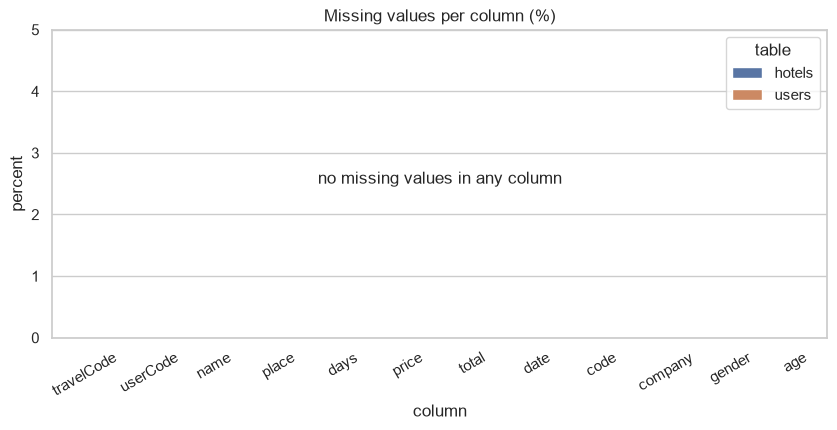

In [8]:
# Visualizing the missing values
# percentage of missing values per column for the hotels and users tables
missing = pd.concat([
    hotels_raw.isnull().mean().mul(100).rename("percent").to_frame().assign(table="hotels"),
    users_raw.isnull().mean().mul(100).rename("percent").to_frame().assign(table="users"),
]).reset_index().rename(columns={"index": "column"})

plt.figure(figsize=(10, 4))
sns.barplot(data=missing, x="column", y="percent", hue="table")
plt.ylim(0, 5)
plt.title("Missing values per column (%)")
plt.text(0.5, 0.5, "no missing values in any column", transform=plt.gca().transAxes, ha="center", fontsize=12)
plt.xticks(rotation=30)
plt.show()

### What did you know about your dataset?

The data has three tables. hotels.csv has 40,552 hotel stays and 8 columns, users.csv has 1,340 users and 5 columns, and flights.csv has 271,888 flight legs and 10 columns. There are no missing values and no duplicate rows in any of them, and every travelCode appears only once in the hotels table, so one trip has at most one hotel stay. The date column is stored as text and needs to be converted.

The hotels table is the main one for the recommender. The users table adds company, gender and age, and the flights table helps me work out where each user lives, since the users table has no city column.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
print("hotels :", hotels_raw.columns.tolist())
print("users  :", users_raw.columns.tolist())
print("flights:", flights_raw.columns.tolist())

hotels : ['travelCode', 'userCode', 'name', 'place', 'days', 'price', 'total', 'date']
users  : ['code', 'company', 'name', 'gender', 'age']
flights: ['travelCode', 'userCode', 'from', 'to', 'flightType', 'price', 'time', 'distance', 'agency', 'date']


In [10]:
# Dataset Describe
display(hotels_raw.describe(include="all").T)
display(users_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
travelCode,40552.0,NaN,NaN,NaN,67911.794461,39408.199333,0.0,33696.75,67831.0,102211.25,135942.0
userCode,40552.0,NaN,NaN,NaN,666.963726,391.136794,0.0,323.0,658.0,1013.0,1339.0
name,40552,9,Hotel K,5094,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place,40552,9,Salvador (BH),5094,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days,40552.0,NaN,NaN,NaN,2.499679,1.119326,1.0,1.0,2.0,4.0,4.0
price,40552.0,NaN,NaN,NaN,214.439554,76.742305,60.39,165.99,242.88,263.41,313.02
total,40552.0,NaN,NaN,NaN,536.229513,319.331482,60.39,247.62,495.24,742.86,1252.08
date,40552,199,10/03/2019,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
code,1340.0,NaN,NaN,NaN,669.5,386.968991,0.0,334.75,669.5,1004.25,1339.0
company,1340,5,4You,453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,1340,1338,David Robinson,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1340,3,male,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1340.0,NaN,NaN,NaN,42.742537,12.869779,21.0,32.0,42.0,54.0,65.0


### Variables Description 

**hotels.csv**
- travelCode: id of the trip, the same id is used in flights.csv
- userCode: id of the user, links to code in users.csv
- name: hotel name (9 hotels, Hotel A to Hotel Z)
- place: city of the hotel, each hotel is in a different city
- days: number of nights booked (1 to 4)
- price: price per day, fixed for each hotel (60.39 to 313.02)
- total: price x days, the amount paid for the stay
- date: check in date (September 2019 to July 2023)

**users.csv**
- code: user id
- company: the corporate client the user works for (5 companies)
- name: full name of the user
- gender: male, female or none
- age: age in years (21 to 65)

**flights.csv** (only used for context here)
- travelCode, userCode: same ids as above
- from, to: origin and destination city of the flight
- flightType, price, time, distance, agency, date: details of the flight leg

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for name, df in [("hotels", hotels_raw), ("users", users_raw)]:
    print(f"--- {name}")
    for col in df.columns:
        print(f"{col:<12} {df[col].nunique():>6} unique values")

print("\nHotels and their cities:")
print(hotels_raw.groupby("name")["place"].unique())

--- hotels
travelCode    40552 unique values
userCode       1310 unique values
name              9 unique values
place             9 unique values
days              4 unique values
price             9 unique values
total            36 unique values
date            199 unique values
--- users
code           1340 unique values
company           5 unique values
name           1338 unique values
gender            3 unique values
age              45 unique values

Hotels and their cities:
name
Hotel A      [Florianopolis (SC)]
Hotel AF         [Sao Paulo (SP)]
Hotel AU            [Recife (PE)]
Hotel BD             [Natal (RN)]
Hotel BP          [Brasilia (DF)]
Hotel BW      [Campo Grande (MS)]
Hotel CB    [Rio de Janeiro (RJ)]
Hotel K           [Salvador (BH)]
Hotel Z            [Aracaju (SE)]
Name: place, dtype: object


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
hotels = hotels_raw.copy()
users = users_raw.copy()
flights = flights_raw.copy()

# dates come as month/day/year strings
hotels["date"] = pd.to_datetime(hotels["date"], format="%m/%d/%Y")
flights["date"] = pd.to_datetime(flights["date"], format="%m/%d/%Y")

# one row per hotel: the city it is in and its price per day (the price never changes)
def hotel_table(hotels):
    """One row per hotel with its city and price per day, sorted by hotel name."""
    return (hotels.groupby("name")
            .agg(place=("place", "first"), price_per_day=("price", "first"))
            .reset_index()
            .rename(columns={"name": "hotel"}))

hotel_info = hotel_table(hotels)
hotel_info["bookings"] = hotel_info["hotel"].map(hotels["name"].value_counts())
print(hotel_info, "\n")

# users do not have a city column, so I take the city most of their outbound flights leave from
def home_cities(flights):
    """Home city of each user = the city most of their outbound flights leave from."""
    outbound = flights.sort_values(["travelCode", "date"]).drop_duplicates("travelCode")
    return outbound.groupby("userCode")["from"].agg(lambda s: s.value_counts().index[0])

home = home_cities(flights)
users["home"] = users["code"].map(home).fillna("unknown")
users["age_group"] = pd.cut(users["age"], bins=[0, 30, 40, 50, 100],
                            labels=["21-30", "31-40", "41-50", "51-65"]).astype(str)

# all hotel stays in time order per user, with the user details attached
stays = (hotels.sort_values(["userCode", "date", "travelCode"])
         .merge(users[["code", "company", "gender", "age", "age_group", "home"]].rename(columns={"code": "userCode"}),
                on="userCode", how="left")
         .reset_index(drop=True))
stays["in_home_city"] = stays["place"] == stays["home"]
stays["month"] = stays["date"].dt.to_period("M").dt.to_timestamp()

# one row per user that booked at least one hotel
user_summary = stays.groupby("userCode").agg(
    n_stays=("travelCode", "count"),
    distinct_hotels=("name", "nunique"),
    avg_days=("days", "mean"),
    avg_price_per_day=("price", "mean"),
    avg_total=("total", "mean"),
    total_spend=("total", "sum"),
    age=("age", "first"),
).reset_index()
# loyalty = share of the user's stays that went to their most used hotel
user_summary["loyalty"] = stays.groupby("userCode")["name"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).values

# a few numbers that help with the story
trip_link = hotels.merge(flights.drop_duplicates("travelCode")[["travelCode", "to"]], on="travelCode", how="left")
print("users with at least one hotel stay:", stays["userCode"].nunique(), "of", len(users))
print("share of trips that include a hotel:", round(hotels["travelCode"].nunique() / flights["travelCode"].nunique(), 3))
print("hotel city equals the flight destination of the same trip:", (trip_link["place"] == trip_link["to"]).mean())
print("share of stays in the user's own home city:", round(stays["in_home_city"].mean(), 4))
print("date range:", stays["date"].min().date(), "to", stays["date"].max().date())
print()
print(user_summary.describe().round(2))

      hotel                place  price_per_day  bookings
0   Hotel A   Florianopolis (SC)         313.02      3330
1  Hotel AF       Sao Paulo (SP)         139.10      4828
2  Hotel AU          Recife (PE)         312.83      4467
3  Hotel BD           Natal (RN)         242.88      4829
4  Hotel BP        Brasilia (DF)         247.62      4437
5  Hotel BW    Campo Grande (MS)          60.39      4333
6  Hotel CB  Rio de Janeiro (RJ)         165.99      5029
7   Hotel K        Salvador (BH)         263.41      5094
8   Hotel Z         Aracaju (SE)         208.04      4205 



users with at least one hotel stay: 1310 of 1340
share of trips that include a hotel: 0.298
hotel city equals the flight destination of the same trip: 1.0
share of stays in the user's own home city: 0.0396
date range: 2019-09-26 to 2023-07-13

       userCode  n_stays  distinct_hotels  avg_days  avg_price_per_day  avg_total  total_spend      age  loyalty
count   1310.00  1310.00          1310.00   1310.00            1310.00    1310.00      1310.00  1310.00  1310.00
mean     668.79    30.96             7.42      2.50             213.97     535.63     16599.37    42.72     0.26
std      387.51    17.98             1.88      0.31              24.74      93.56      9853.29    12.86     0.13
min        0.00     1.00             1.00      1.00              60.39      60.39        60.39    21.00     0.13
25%      332.25    15.00             7.00      2.33             201.17     489.09      8030.74    32.00     0.19
50%      668.50    30.00             8.00      2.50             213.60     533

### What all manipulations have you done and insights you found?

What I did:

- converted the date columns from text to datetime
- built a small hotel table with the city, price per day and number of bookings of each hotel
- worked out a home city for every user: the city most of their outbound flights (the first leg of each trip) leave from. 5 users have no flights, so their home city is "unknown"
- added an age group (21-30, 31-40, 41-50, 51-65) to the users
- joined the user details onto every hotel stay and sorted the stays by user and date, which the time based evaluation needs later
- made a user level summary: number of stays, distinct hotels, average days, average price, total spend and "loyalty" (share of stays at the user's most used hotel)

What I found:

- only 9 hotels, each in its own city with a fixed price. Hotel A is the least booked (3,330 stays) and also the most expensive (313.02 per day)
- the hotel city always matches the flight destination of the same trip (1.0), and 29.8% of trips include a hotel
- only 3.96% of stays are in the user's own home city, a first hint that people don't book hotels where they live
- the average user has 31 stays and has tried 7.4 of the 9 hotels, and loyalty is low (on average 26% of stays go to the favourite hotel)

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Bookings per hotel (Univariate)

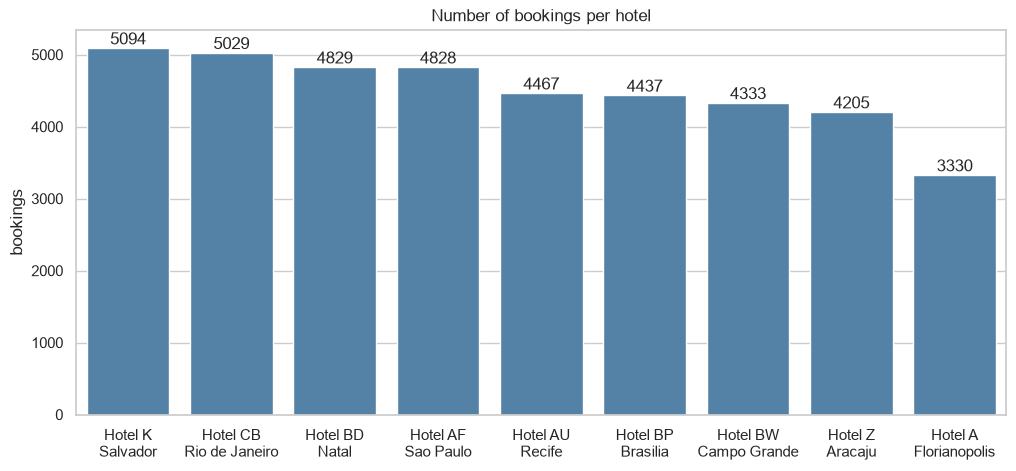

In [13]:
# Chart - 1 visualization code
# how many bookings each hotel got
order = hotel_info.sort_values("bookings", ascending=False)
labels = order["hotel"] + "\n" + order["place"].str.replace(r" \(.*\)", "", regex=True)

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=labels, y=order["bookings"], color="steelblue")
ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Number of bookings per hotel")
plt.xlabel("")
plt.ylabel("bookings")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the simplest way to compare counts between categories, and here I want to see how the bookings are split across the 9 hotels. I put the city under each hotel name because every hotel is in a different city.

##### 2. What is/are the insight(s) found from the chart?

Hotel K in Salvador is the most booked with 5,094 stays, closely followed by Hotel CB in Rio de Janeiro (5,029) and Hotels BD and AF (about 4,830 each). Hotel A in Florianopolis is clearly last with 3,330 stays, which is 8.2% of all bookings against 12.6% for Hotel K. Apart from Hotel A the hotels are quite close to each other.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. A recommender that only pushes the top 3 hotels would send most people to K, CB and BD and almost nobody to Hotel A, so knowing that demand is fairly even tells me the model should spread its suggestions over the whole catalog. The low number for Hotel A could be read as a negative point, but as I found later it's mostly because a large group of users lives in Florianopolis and never stays there. If the business only looked at raw bookings it might wrongly think Hotel A is unpopular.

#### Chart - 2 - Length of stay (Univariate)

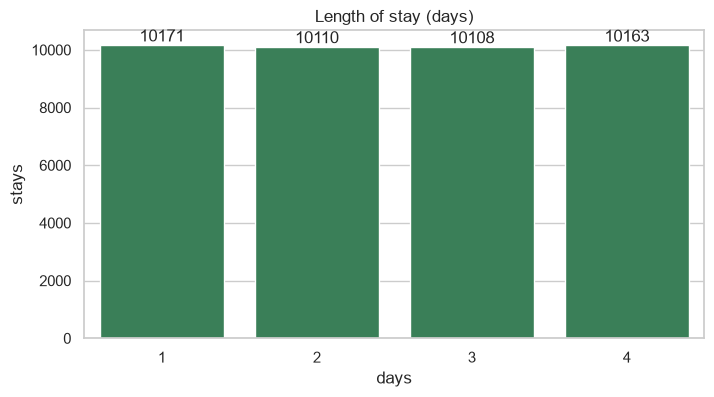

In [14]:
# Chart - 2 visualization code
# how long people stay
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=stays, x="days", color="seagreen")
ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Length of stay (days)")
plt.ylabel("stays")
plt.show()

##### 1. Why did you pick the specific chart?

Stay length only has 4 values (1 to 4 days), so a count plot shows the whole distribution directly.

##### 2. What is/are the insight(s) found from the chart?

All four stay lengths are almost exactly equally common: 10,171 one day stays, 10,110 two day, 10,108 three day and 10,163 four day stays. The average stay is 2.5 days.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It helps with planning a bit: there is no typical stay length, so hotels should expect a steady mix of short and long stays. For the recommender it means the stay length says nothing about which hotel a person picks (I confirm this later with a Cramer's V of 0.017). Nothing here points to negative growth, but it also means there is no easy upsell like "people who stay longer prefer hotel X".

#### Chart - 3 - Total amount per stay (Univariate)

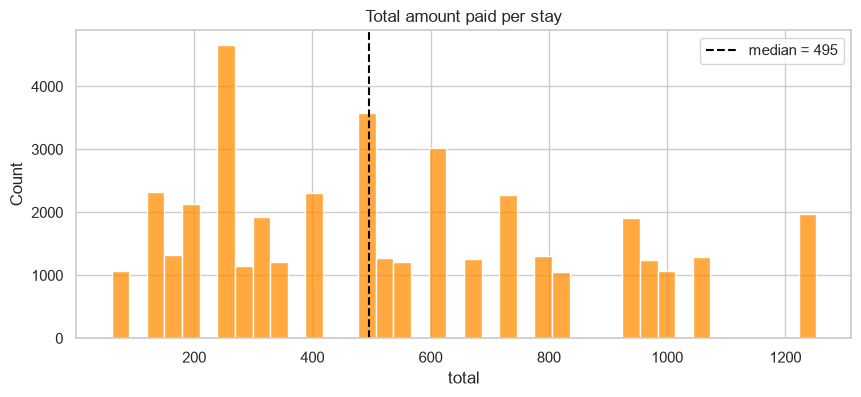

In [15]:
# Chart - 3 visualization code
# distribution of the total bill per stay
plt.figure(figsize=(10, 4))
sns.histplot(stays["total"], bins=40, color="darkorange")
plt.axvline(stays["total"].median(), color="black", linestyle="--", label=f"median = {stays['total'].median():.0f}")
plt.title("Total amount paid per stay")
plt.xlabel("total")
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is the usual chart for the distribution of a numeric column like the total amount per stay.

##### 2. What is/are the insight(s) found from the chart?

Totals go from 60.39 to 1,252.08 with a median of 495 (the mean is 536). The histogram looks spiky because there are only 36 possible totals: 9 hotel prices times 4 stay lengths. Most stays cost between 250 and 750.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the total is fully explained by the hotel price and the number of days, so revenue per hotel is easy to plan. The negative side is that prices never change in this data, there is no seasonal or demand based pricing, so the company may be leaving money on the table in busy months like October 2019.

#### Chart - 4 - Stays per user (Univariate)

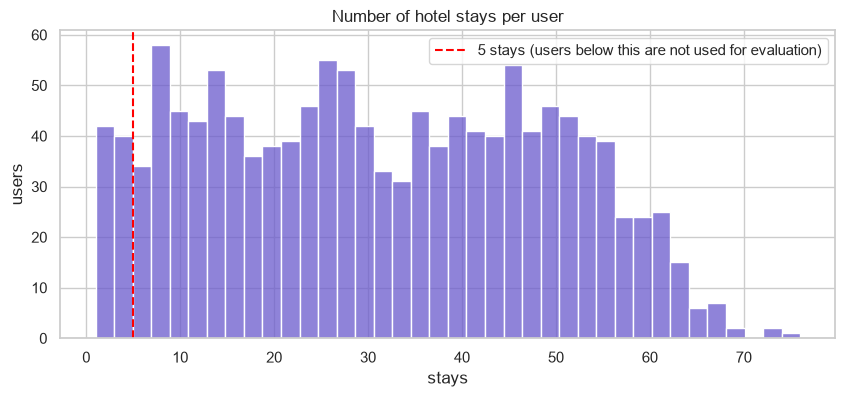

users with fewer than 5 stays: 82


In [16]:
# Chart - 4 visualization code
# how many hotel stays each user has (this matters a lot for a recommender)
plt.figure(figsize=(10, 4))
sns.histplot(user_summary["n_stays"], bins=38, color="slateblue")
plt.axvline(5, color="red", linestyle="--", label="5 stays (users below this are not used for evaluation)")
plt.title("Number of hotel stays per user")
plt.xlabel("stays")
plt.ylabel("users")
plt.legend()
plt.show()

print("users with fewer than 5 stays:", (user_summary["n_stays"] < 5).sum())

##### 1. Why did you pick the specific chart?

A histogram shows how many stays each user has. This matters a lot for a recommender because users with very little history are hard to personalise for.

##### 2. What is/are the insight(s) found from the chart?

Users have between 1 and 76 stays, with a mean of 31 and a median of 30, and the distribution is fairly flat between about 5 and 60 stays. Only 82 users have fewer than 5 stays, and 30 users in the users table have no hotel stay at all.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This is good for the business because most users are repeat customers, which is exactly where a recommender can add value. The 82 light users and the 30 users without stays are a cold start problem: if they get poor suggestions they may book somewhere else, so the model needs a sensible fallback for them (popularity).

#### Chart - 5 - Bookings per month (Univariate, over time)

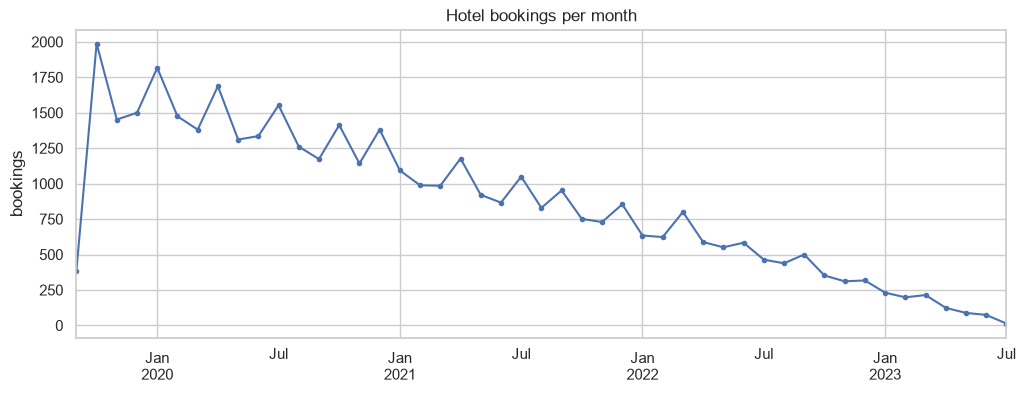

peak month: 2019-10 1988
last full month: 2023-06 74


In [17]:
# Chart - 5 visualization code
# bookings per month over time
monthly = stays.groupby("month").size()

plt.figure(figsize=(12, 4))
monthly.plot(marker="o", markersize=3)
plt.title("Hotel bookings per month")
plt.xlabel("")
plt.ylabel("bookings")
plt.show()

print("peak month:", monthly.idxmax().strftime("%Y-%m"), monthly.max())
print("last full month:", monthly.index[-2].strftime("%Y-%m"), monthly.iloc[-2])

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for a value over time, here the number of bookings per month.

##### 2. What is/are the insight(s) found from the chart?

Bookings peak right at the start with 1,988 in October 2019 and then drop steadily. By June 2023 there are only 74 bookings in the month (July 2023 is only partly in the data).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This is the clearest negative growth signal in the data: monthly hotel bookings fell by more than 95% in under four years. Part of it might be how the data was collected, but if it's real the company is losing hotel business, which is a good reason to invest in better suggestions for existing customers. It also suggests recent behaviour should count more than old behaviour, so I tested a recency weight in the models.

#### Chart - 6 - Price per day by hotel (Bivariate, categorical - numerical)

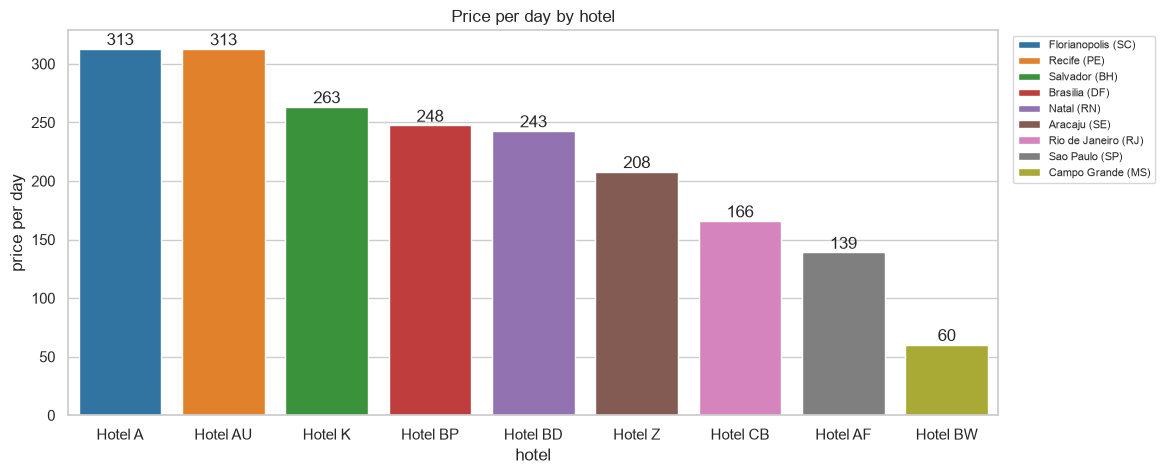

In [18]:
# Chart - 6 visualization code
# price per day of each hotel
order = hotel_info.sort_values("price_per_day", ascending=False)

plt.figure(figsize=(12, 5))
ax = sns.barplot(data=order, x="hotel", y="price_per_day", hue="place", dodge=False, palette="tab10")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f")
plt.title("Price per day by hotel")
plt.ylabel("price per day")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares one number (price per day) across categories (hotels), and colouring by city makes it clear that each hotel is in a different city.

##### 2. What is/are the insight(s) found from the chart?

Prices vary a lot. Hotel A in Florianopolis (313.02) and Hotel AU in Recife (312.83) are the most expensive, and Hotel BW in Campo Grande is by far the cheapest at 60.39, about 5 times cheaper. Hotel AF in Sao Paulo (139.10) and Hotel CB in Rio de Janeiro (165.99) are the other budget options.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the price range makes a budget filter useful, so I added a max_price option to the recommend function. A slightly negative point is that price doesn't seem to drive choice: the cheapest hotel BW has 4,333 bookings and the expensive AU has 4,467. So discounting alone probably wouldn't bring many more bookings.

#### Chart - 7 - Total amount by length of stay (Bivariate, categorical - numerical)

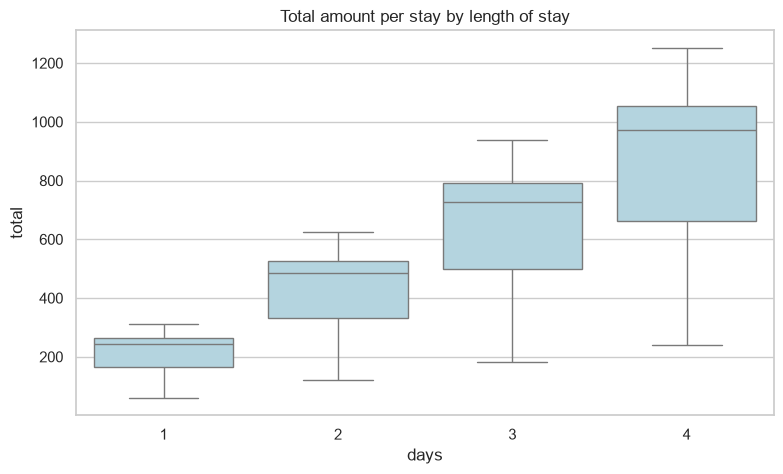

days
1    242.88
2    485.76
3    728.64
4    971.52
Name: total, dtype: float64


In [19]:
# Chart - 7 visualization code
# total amount per stay, split by length of stay
plt.figure(figsize=(9, 5))
sns.boxplot(data=stays, x="days", y="total", color="lightblue")
plt.title("Total amount per stay by length of stay")
plt.show()

print(stays.groupby("days")["total"].median())

##### 1. Why did you pick the specific chart?

A box plot shows the spread of a numeric variable (total amount) for each category (days), so it's good for comparing the four stay lengths.

##### 2. What is/are the insight(s) found from the chart?

The median total grows in a straight line with the length of stay: 242.88 for 1 day, 485.76 for 2, 728.64 for 3 and 971.52 for 4 days. The boxes also get wider with more days, because the price gap between hotels is multiplied by the number of days.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It confirms there are no discounts for longer stays (total = price x days). That is an opportunity: a small discount for 3 or 4 day stays could make longer trips more attractive. Nothing here points to negative growth on its own.

#### Chart - 8 - Hotel share by company (Bivariate, categorical - categorical)

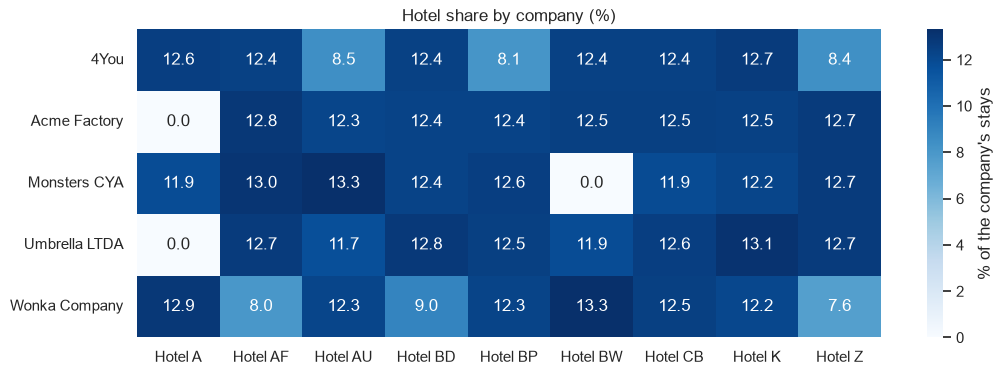

In [20]:
# Chart - 8 visualization code
# which hotels each company's employees book (row percentages)
company_share = pd.crosstab(stays["company"], stays["name"], normalize="index") * 100

plt.figure(figsize=(12, 4))
sns.heatmap(company_share, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of the company's stays"})
plt.title("Hotel share by company (%)")
plt.xlabel("")
plt.ylabel("")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of row percentages is a good way to compare two categorical variables (company and hotel) and spot any cell that stands out.

##### 2. What is/are the insight(s) found from the chart?

Most cells are around 12.5%, but some are much lower. Acme Factory and Umbrella LTDA never stayed at Hotel A in Florianopolis (0.0%) and Monsters CYA never stayed at Hotel BW in Campo Grande (0.0%). 4You has lower shares (about 8%) for Hotels AU, BP and Z, and Wonka Company for Hotels AF, BD and Z. It looks like each company is based in one or more cities and its staff don't book hotels in those cities.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this is one of the most useful findings. Suggesting the hotel in a user's base city would waste one of the three slots, so the model should push those hotels down. No negative growth insight here, but it shows that company and home city are the only user attributes with a clear link to hotel choice.

#### Chart - 9 - Hotel city by home city (Bivariate, categorical - categorical)

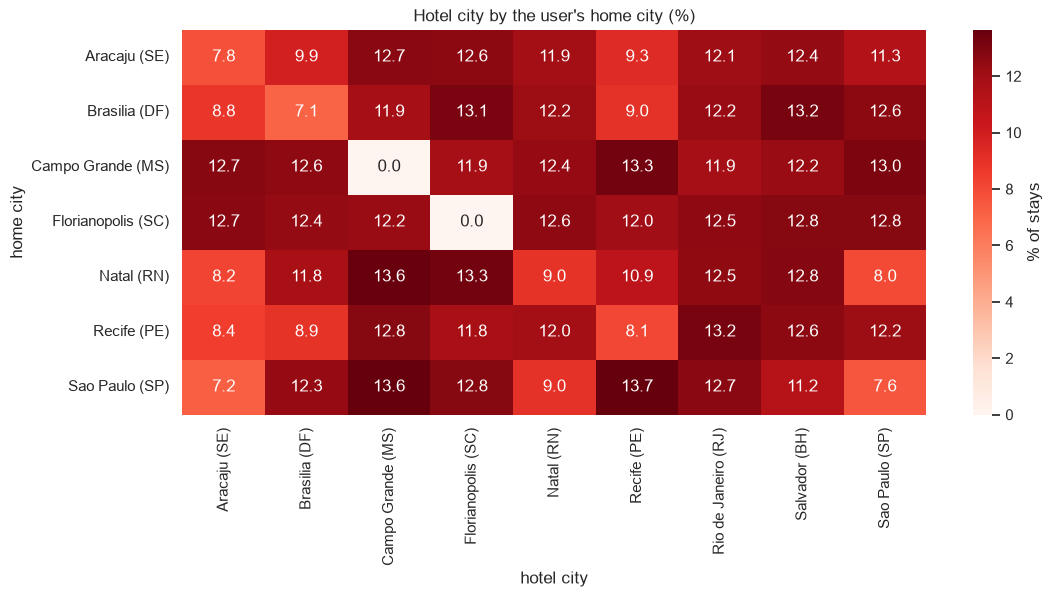

In [21]:
# Chart - 9 visualization code
# which hotels people from each home city book (row percentages)
home_share = pd.crosstab(stays["home"], stays["place"], normalize="index") * 100

plt.figure(figsize=(12, 5))
sns.heatmap(home_share, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% of stays"})
plt.title("Hotel city by the user's home city (%)")
plt.xlabel("hotel city")
plt.ylabel("home city")
plt.show()

##### 1. Why did you pick the specific chart?

Same idea as chart 8 but with the home city I worked out from the flights. With row percentages the diagonal (home city = hotel city) is easy to spot.

##### 2. What is/are the insight(s) found from the chart?

Users from Campo Grande and Florianopolis have 0.0% of their stays in their own city. For the other home cities the diagonal is also one of the lowest values in the row (Aracaju 7.8%, Brasilia 7.1%, Recife 8.1%, Sao Paulo 7.6%, Natal 9.0%) against roughly 12 to 13% for the other cities. These are not exactly zero because 4You and Wonka employees fly out of several cities, so my home city guess is not always right for them.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this directly gave me the home city penalty in the final model: the hotel in the user's own city is very unlikely to be booked, so not showing it frees a slot for something useful. No negative growth here.

#### Chart - 10 - Hotel share by age group (Bivariate, categorical - categorical)

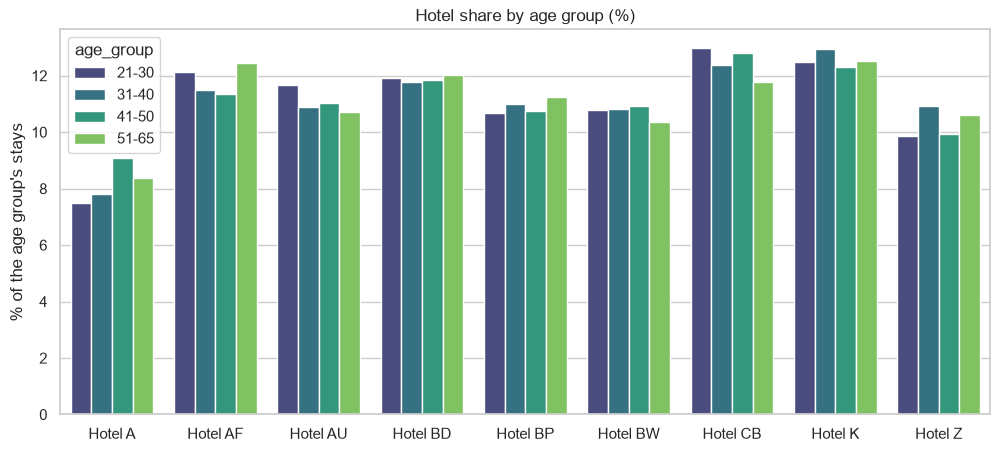

In [22]:
# Chart - 10 visualization code
# hotel share by age group
age_share = (pd.crosstab(stays["name"], stays["age_group"], normalize="columns") * 100).reset_index().melt(
    id_vars="name", var_name="age_group", value_name="percent")

plt.figure(figsize=(12, 5))
sns.barplot(data=age_share, x="name", y="percent", hue="age_group", palette="viridis")
plt.title("Hotel share by age group (%)")
plt.xlabel("")
plt.ylabel("% of the age group's stays")
plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart lets me compare the hotel shares of each age group side by side.

##### 2. What is/are the insight(s) found from the chart?

The bars are very similar across age groups for every hotel, mostly within 1 percentage point. The biggest gap is Hotel A, where 21 to 30 year olds have 7.5% of their stays and 41 to 50 year olds 9.1%. Hotel CB is a little more popular with younger users (13.0% for 21-30 against 11.8% for 51-65).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It tells me age is not a useful segment for recommendations (Cramer's V is only 0.02), which saves effort on age based campaigns. Not a negative insight as such, but it does mean that targeting hotels by age group would not move bookings much.

#### Chart - 11 - Total amount per stay by gender (Bivariate, categorical - numerical)

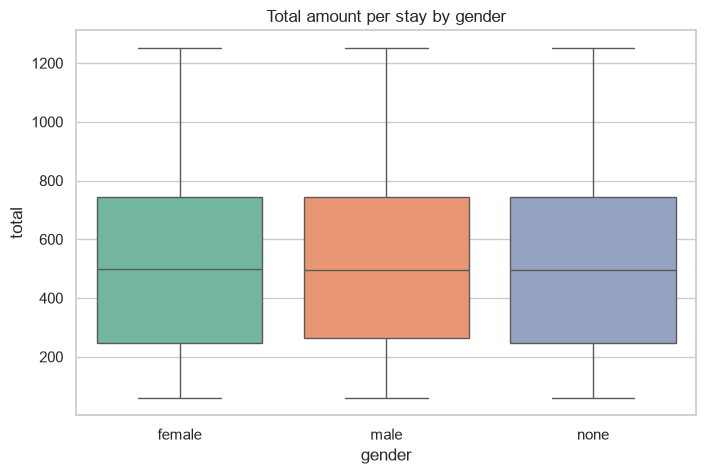

          mean  median  count
gender                       
female  535.57  497.97  13690
male    537.34  495.24  13585
none    535.77  495.24  13277


In [23]:
# Chart - 11 visualization code
# amount spent per stay for male / female / none
plt.figure(figsize=(8, 5))
sns.boxplot(data=stays, x="gender", y="total", order=["female", "male", "none"], palette="Set2")
plt.title("Total amount per stay by gender")
plt.show()

print(stays.groupby("gender")["total"].agg(["mean", "median", "count"]).round(2))

##### 1. Why did you pick the specific chart?

A box plot compares the distribution of the amount per stay between the three gender values.

##### 2. What is/are the insight(s) found from the chart?

The three groups are practically identical: the mean total is 535.57 for female, 537.34 for male and 535.77 for none, and the medians are 498 and 495. The number of stays is almost equal too (13,690, 13,585 and 13,277).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It shows spending does not depend on gender, so there is no reason to show different hotels or prices by gender, which is also the fairer approach. Not a negative insight, just a feature we can leave out.

#### Chart - 12 - Distinct hotels vs number of stays (Bivariate, numerical - numerical)

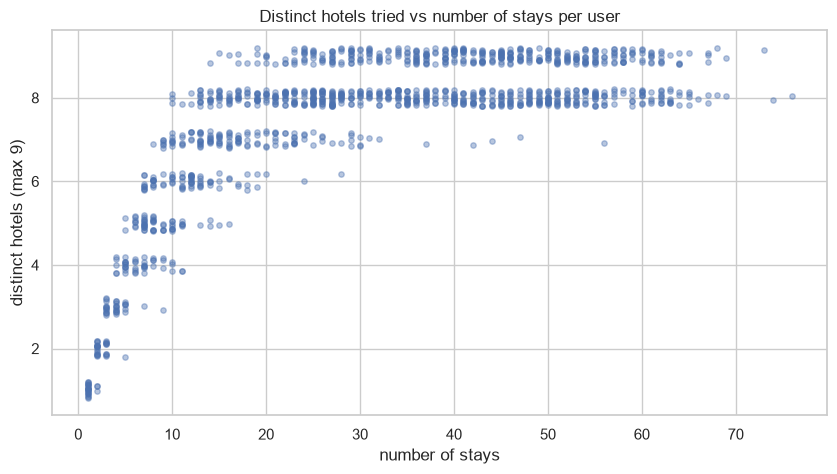

correlation: 0.707
users who tried 8 or 9 of the 9 hotels: 70.3 %


In [24]:
# Chart - 12 visualization code
# do users stick to a few hotels or try all of them?
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.2, 0.2, len(user_summary))

plt.figure(figsize=(10, 5))
plt.scatter(user_summary["n_stays"], user_summary["distinct_hotels"] + jitter, alpha=0.4, s=15)
plt.title("Distinct hotels tried vs number of stays per user")
plt.xlabel("number of stays")
plt.ylabel("distinct hotels (max 9)")
plt.show()

print("correlation:", round(user_summary["n_stays"].corr(user_summary["distinct_hotels"]), 3))
print("users who tried 8 or 9 of the 9 hotels:", round((user_summary["distinct_hotels"] >= 8).mean() * 100, 1), "%")

##### 1. Why did you pick the specific chart?

A scatter plot is the standard chart for two numeric variables. I added a small jitter on the y axis because distinct hotels is a whole number and the points would sit on top of each other.

##### 2. What is/are the insight(s) found from the chart?

The more stays a user has, the more hotels they have tried (correlation 0.707). After about 20 stays almost everyone has tried 8 or 9 hotels, and overall 70.3% of users have tried at least 8 of the 9.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This changes how a recommender should work here. Recommending "new" hotels the user has never tried isn't possible for most users, because they have already tried almost all of them, so the useful question is which of the known hotels they will pick next. For the business it also shows customers are not loyal to one hotel, which is a slightly negative point since there is no strong repeat preference to build on.

#### Chart - 13 - Hotel to hotel similarity (Multivariate)

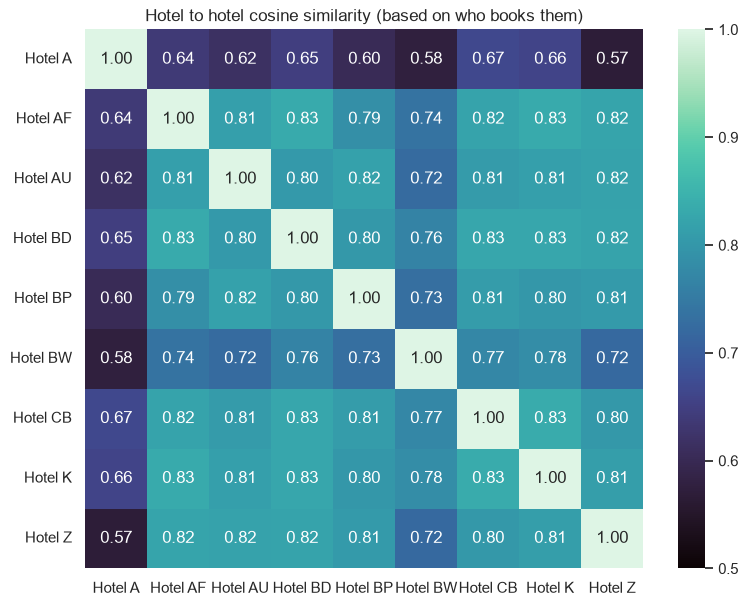

off diagonal similarity: min 0.57, max 0.83, mean 0.76


In [25]:
# Chart - 13 visualization code
# item to item similarity: two hotels are similar if the same users book both of them
user_hotel = pd.crosstab(stays["userCode"], stays["name"])
hotel_sim = pd.DataFrame(cosine_similarity(user_hotel.T), index=user_hotel.columns, columns=user_hotel.columns)

plt.figure(figsize=(9, 7))
sns.heatmap(hotel_sim, annot=True, fmt=".2f", cmap="mako", vmin=0.5, vmax=1)
plt.title("Hotel to hotel cosine similarity (based on who books them)")
plt.xlabel("")
plt.ylabel("")
plt.show()

off_diag = hotel_sim.values[~np.eye(len(hotel_sim), dtype=bool)]
print(f"off diagonal similarity: min {off_diag.min():.2f}, max {off_diag.max():.2f}, mean {off_diag.mean():.2f}")

##### 1. Why did you pick the specific chart?

For item based collaborative filtering two hotels are similar if the same users book both of them. A heatmap of the cosine similarity between the hotel columns of the user x hotel matrix shows this for every pair at once.

##### 2. What is/are the insight(s) found from the chart?

All hotels are very similar to each other. The off diagonal values go from 0.57 to 0.83 with a mean of 0.76. The lowest values are all in the Hotel A row (0.57 to 0.67) and then Hotel BW (0.72 to 0.78), the two hotels that whole companies never book because they are based in those cities. Between the other seven hotels the similarity is 0.79 to 0.83.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It's an early warning that collaborative filtering will struggle: if every hotel is booked by roughly the same people, there are no clear "people who liked X also liked Y" patterns to learn. That turned out to be true in the modelling part. On the positive side it confirms the home city effect again, since the only real structure in the matrix comes from Hotels A and BW.

#### Chart - 14 - Correlation Heatmap (Multivariate)

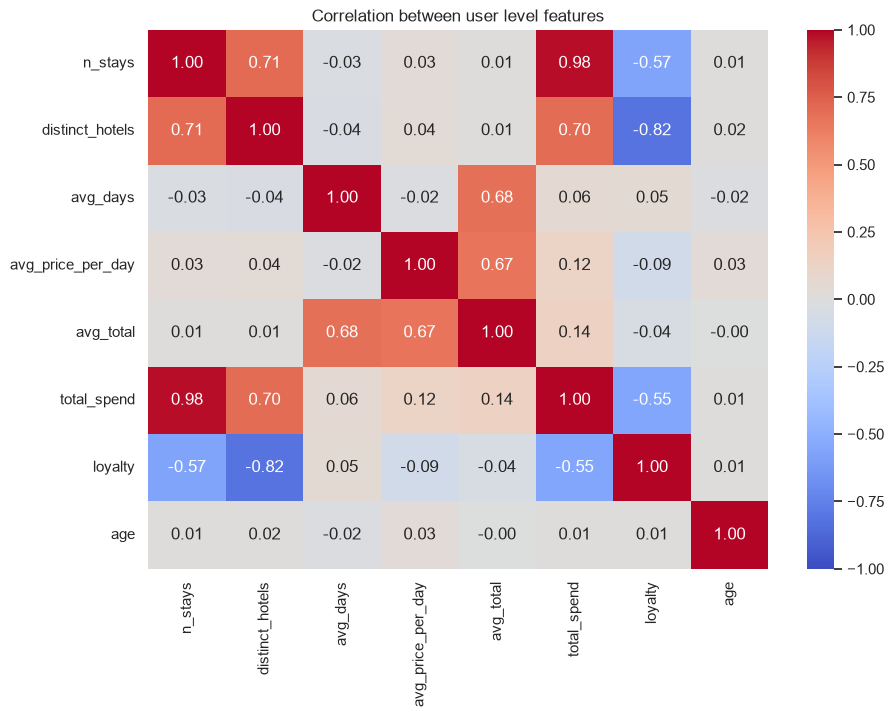

In [26]:
# Correlation Heatmap visualization code
num_cols = ["n_stays", "distinct_hotels", "avg_days", "avg_price_per_day", "avg_total", "total_spend", "loyalty", "age"]

plt.figure(figsize=(10, 7))
sns.heatmap(user_summary[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between user level features")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows the linear relationship between every pair of numeric user level features in one picture, so it's easy to see which features carry the same information.

##### 2. What is/are the insight(s) found from the chart?

n_stays and total_spend are almost the same thing (0.98). distinct_hotels goes up with n_stays (0.71) and loyalty goes down strongly with distinct_hotels (-0.82) and n_stays (-0.57), so frequent travellers spread their stays over more hotels. avg_total depends on avg_days (0.68) and avg_price_per_day (0.67), as expected. Age is not correlated with anything (all values between -0.02 and 0.03).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Since frequent travellers are not loyal to one hotel, the model should not simply repeat a user's favourite hotel, which is why I mix the user's history with popularity. It also shows that age is useless as a feature. The negative side is the drop in loyalty with more stays: the more someone travels, the less attached they are to any one hotel, so there's little brand loyalty to build on.

#### Chart - 15 - Pair Plot (Multivariate)

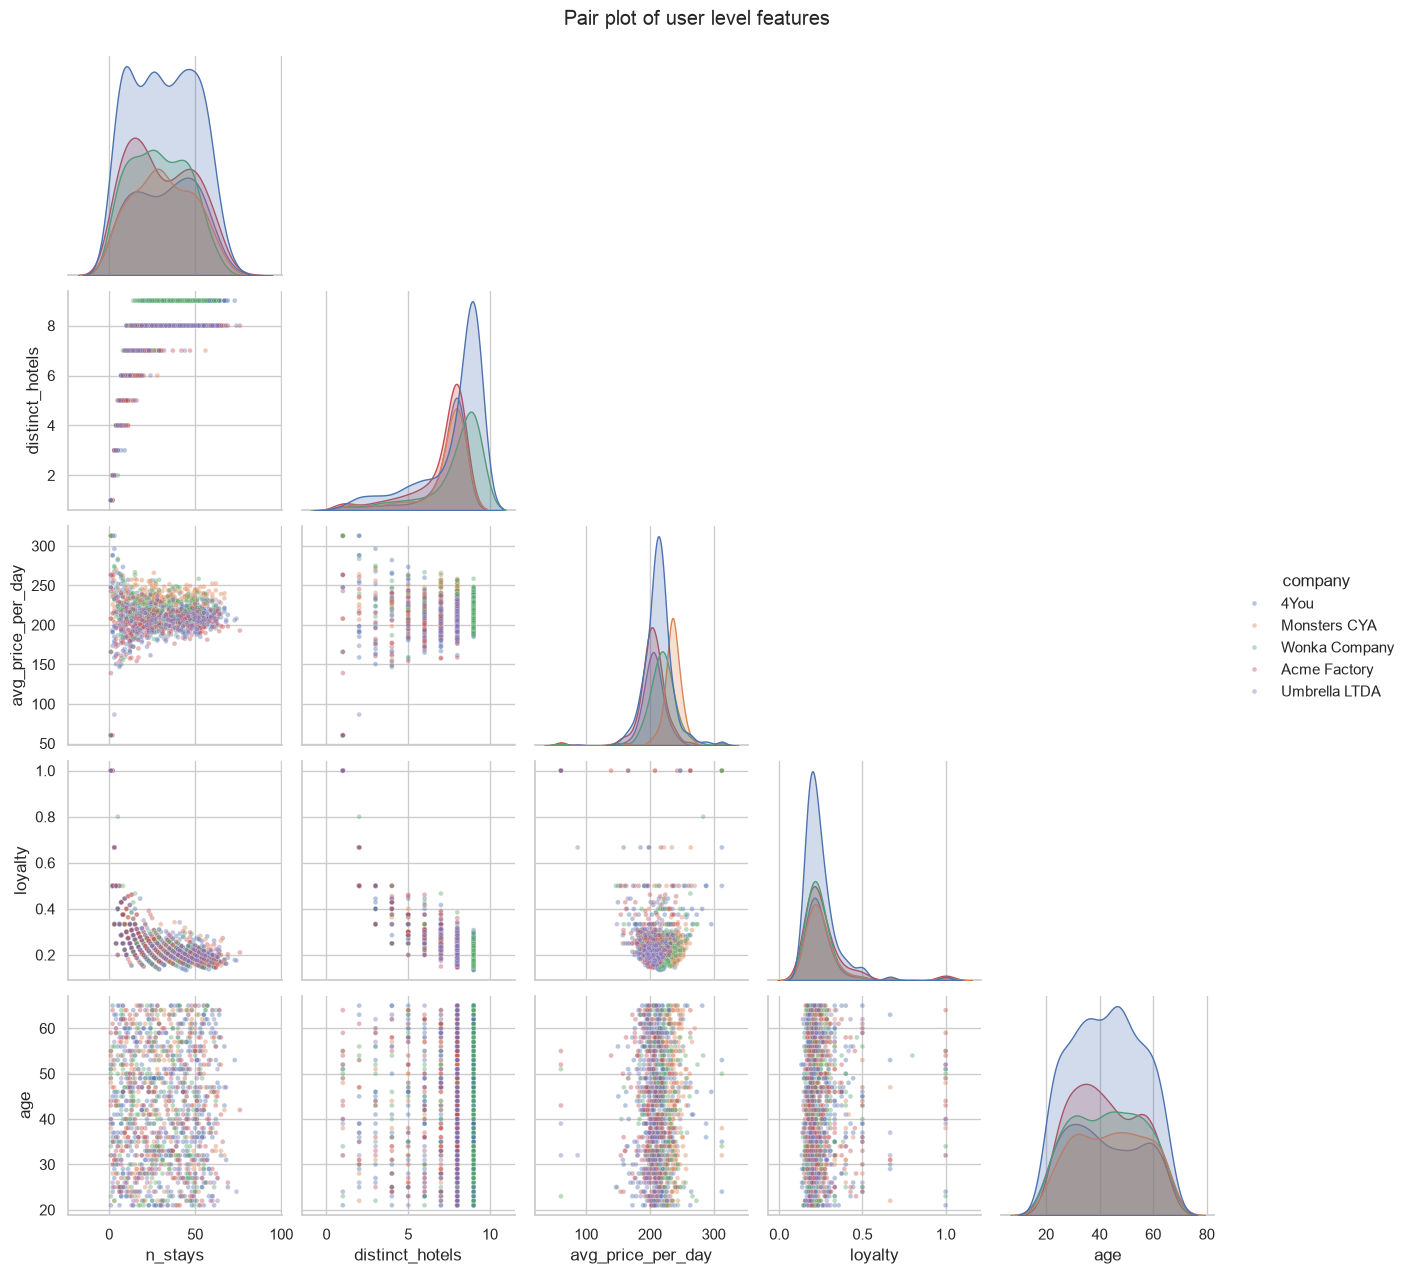

In [27]:
# Pair Plot visualization code
pair_df = user_summary.merge(users[["code", "company"]], left_on="userCode", right_on="code")
sns.pairplot(pair_df[["n_stays", "distinct_hotels", "avg_price_per_day", "loyalty", "age", "company"]],
             hue="company", plot_kws={"alpha": 0.4, "s": 12}, corner=True)
plt.suptitle("Pair plot of user level features", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pair of the main user level features together with the distribution of each one, and colouring by company lets me check whether any company behaves differently.

##### 2. What is/are the insight(s) found from the chart?

Most companies overlap completely. The one clear difference is Monsters CYA, whose average price per day peaks around 240 while the others peak near 210. That fits chart 8, Monsters CYA never stays at Hotel BW, the cheapest hotel at 60.39 per day. The loyalty vs n_stays panel shows a clear curve: users with only a few stays look loyal just because they have few stays. Age doesn't separate anything.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

It helps explain average spend per company (Monsters CYA pays more per day because it skips the cheapest hotel), which is useful when negotiating deals with corporate clients. I don't see a new negative growth insight here beyond what charts 5 and 14 already showed.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts I picked three statements to test:

1. Users book fewer hotels in their own home city than chance would suggest (charts 8 and 9).
2. Hotel choice does not depend on gender (charts 10 and 11 showed no differences between groups).
3. Frequent travellers have no personal preference between the hotels outside their home city (charts 12 and 13).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null hypothesis (H0): the share of stays in the user's home city is 1/9 (11.1%), so the home city has no effect on hotel choice.

Alternate hypothesis (H1): the share of stays in the home city is lower than 1/9.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
# H0: the share of stays in the user's home city is 1/9 (home city does not matter)
# H1: the share is lower than 1/9
known_home = stays[stays["home"] != "unknown"]
k = int(known_home["in_home_city"].sum())
n = len(known_home)
result = stats.binomtest(k, n, p=1/9, alternative="less")

print(f"stays in home city: {k} of {n} ({k/n:.2%}), expected under H0: {1/9:.2%}")
print("p-value:", result.pvalue)
print("reject H0" if result.pvalue < 0.05 else "fail to reject H0")

stays in home city: 1606 of 40552 (3.96%), expected under H0: 11.11%
p-value: 0.0
reject H0


##### Which statistical test have you done to obtain P-Value?

A one sided exact binomial test (scipy.stats.binomtest). Only 1,606 of the 40,552 stays (3.96%) are in the home city, and the p-value is 0.0 (too small to print), so I reject H0. People clearly avoid hotels in their own city.

##### Why did you choose the specific statistical test?

Each stay is a yes/no outcome (in the home city or not) and I want to compare the observed proportion with a fixed expected proportion, which is exactly what the binomial test is for. With over 40,000 stays the test has plenty of power.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null hypothesis (H0): hotel choice is independent of gender.

Alternate hypothesis (H1): hotel choice depends on gender.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
# H0: hotel choice is independent of gender
# H1: hotel choice depends on gender
table = pd.crosstab(stays["gender"], stays["name"])
chi2, p, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

print(f"chi2 = {chi2:.2f}, dof = {dof}, p-value = {p:.4f}, Cramer's V = {cramers_v:.4f}")
print("reject H0" if p < 0.05 else "fail to reject H0")

chi2 = 13.58, dof = 16, p-value = 0.6301, Cramer's V = 0.0129
fail to reject H0


##### Which statistical test have you done to obtain P-Value?

A chi-square test of independence on the gender x hotel table (scipy.stats.chi2_contingency), plus Cramer's V to measure the size of the effect. I got chi2 = 13.58 with 16 degrees of freedom and p-value = 0.63, Cramer's V = 0.013. I fail to reject H0, so gender is not linked to hotel choice.

##### Why did you choose the specific statistical test?

Both variables are categorical, and the chi-square test of independence is the standard test for that. All expected counts are far above 5, so its assumptions hold. I added Cramer's V because with this many rows even tiny effects can become significant, and V shows how big the effect really is.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null hypothesis (H0): frequent travellers (40 or more stays) pick uniformly among the hotels outside their home city, so they have no personal preference.

Alternate hypothesis (H1): at least some users prefer certain hotels.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
# H0: every frequent traveller picks uniformly among the hotels outside their home city (no personal taste)
# H1: at least some users have hotels they prefer
places = hotel_info.set_index("hotel")["place"]
chi_stats, dofs, p_values = [], [], []
for user, grp in stays[stays["home"] != "unknown"].groupby("userCode"):
    if len(grp) < 40:      # need enough stays for the expected counts to be >= 5
        continue
    observed = grp["name"].value_counts().reindex(places.index, fill_value=0)
    observed = observed[places.to_numpy(dtype=object) != grp["home"].iloc[0]]
    res = stats.chisquare(observed.values)
    chi_stats.append(res.statistic)
    dofs.append(len(observed) - 1)
    p_values.append(res.pvalue)

chi_stats, dofs, p_values = map(np.array, (chi_stats, dofs, p_values))
combined_p = stats.chi2.sf(chi_stats.sum(), dofs.sum())   # sum of independent chi2 values is chi2 too

print("users tested:", len(chi_stats))
print(f"users with p < 0.05 on their own: {(p_values < 0.05).mean():.1%} (5% expected by chance)")
print(f"combined chi2 = {chi_stats.sum():.1f}, dof = {dofs.sum()}, p-value = {combined_p:.6f}")
print(f"average chi2 / dof = {chi_stats.sum() / dofs.sum():.3f} (1.0 means pure chance)")
print("reject H0" if combined_p < 0.05 else "fail to reject H0")

users tested: 477
users with p < 0.05 on their own: 7.3% (5% expected by chance)
combined chi2 = 3643.3, dof = 3339, p-value = 0.000145
average chi2 / dof = 1.091 (1.0 means pure chance)
reject H0


##### Which statistical test have you done to obtain P-Value?

A chi-square goodness of fit test per user against a uniform distribution, then a combined test by adding up the chi-square values of all 477 users (a sum of independent chi-square values is also chi-square distributed). Combined chi2 = 3,643.3 with 3,339 degrees of freedom and p-value = 0.000145, so I reject H0. But the effect is small: the average chi2 per degree of freedom is 1.091 where pure chance would give 1.0, and only 7.3% of users are significant on their own against 5% expected by chance. So there is some personal preference, just very little of it.

##### Why did you choose the specific statistical test?

Each user's stays are counts over a set of hotels, so a goodness of fit test against equal counts is the natural choice. Testing users one by one gives 477 small tests with low power, so combining them gives one overall answer. I only used users with 40 or more stays so that the expected count per hotel is at least 5, which the chi-square test needs.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation
# there are no nulls in the raw files, but joining the tables creates some gaps
no_hotel_users = sorted(set(users["code"]) - set(stays["userCode"]))
no_flight_users = sorted(set(users["code"]) - set(flights["userCode"]))
print("users with no hotel stay (cold start):", len(no_hotel_users))
print("users with no flights (home city unknown):", len(no_flight_users), no_flight_users)

# home city was already filled with "unknown" for them in the wrangling step
print("unknown home in users table:", (users["home"] == "unknown").sum())
print("nulls left in the stays table:", stays.isnull().sum().sum())

users with no hotel stay (cold start): 30
users with no flights (home city unknown): 5 [385, 670, 863, 893, 983]
unknown home in users table: 5
nulls left in the stays table: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

There are no missing values in the raw files, so nothing had to be imputed there. The gaps come from joining the tables: 30 users have no hotel stays and 5 users (codes 385, 670, 863, 893 and 983) have no flights, so their home city can't be worked out. I set their home city to "unknown" instead of guessing one, and for users without stays the recommender falls back to popularity. Dropping them was not an option because new users are exactly the ones the app still has to handle.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

for col, s in [("total per stay", stays["total"]), ("days", stays["days"]),
               ("stays per user", user_summary["n_stays"]), ("price per day", stays["price"])]:
    print(f"{col:<16} outliers: {iqr_outliers(s)}")

# no treatment needed, every value is a real booking and the ranges are small

total per stay   outliers: 0
days             outliers: 0
stays per user   outliers: 0
price per day    outliers: 0


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used the IQR rule (1.5 x IQR) on the total per stay, days, price per day and stays per user, and found 0 outliers in all of them. The values are naturally bounded (9 fixed prices, 1 to 4 days), so I didn't cap or remove anything. Even if there were very heavy users it wouldn't matter much, because each user's counts are turned into shares later.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns
# hotels become integer ids so they can be used as matrix columns
hotel_ids = {name: i for i, name in enumerate(hotel_info["hotel"])}
stays["hotel_id"] = stays["name"].map(hotel_ids)
print(hotel_ids)

# user attributes that can be used as segments for popularity (kept as labels, no one-hot needed)
user_attr = users.set_index("code")[["company", "age_group", "gender", "home"]]
user_attr.head()

{'Hotel A': 0, 'Hotel AF': 1, 'Hotel AU': 2, 'Hotel BD': 3, 'Hotel BP': 4, 'Hotel BW': 5, 'Hotel CB': 6, 'Hotel K': 7, 'Hotel Z': 8}


,company,age_group,gender,home
code,,,,
0,4You,21-30,male,Brasilia (DF)
1,4You,31-40,male,Aracaju (SE)
2,4You,41-50,female,Aracaju (SE)
3,4You,21-30,female,Brasilia (DF)
4,4You,41-50,female,Recife (PE)


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used simple integer (label) encoding for the hotel names, 0 for Hotel A up to 8 for Hotel Z, because the hotels are only used as column positions in the user x hotel matrix and never as an ordered number in a model. Company, age group, gender and home city are kept as labels and only used to group users for segment popularity, so one-hot encoding wasn't needed.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

This project has no free text. The only string columns are ids and labels (hotel names, cities, company names), so the text steps below don't apply. I kept the cells to follow the template and left a short note in each one.

#### 1. Expand Contraction

In [34]:
# Expand Contraction
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
text_columns = []

#### 2. Lower Casing

In [35]:
# Lower Casing
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
print(hotel_info['hotel'].tolist())

['Hotel A', 'Hotel AF', 'Hotel AU', 'Hotel BD', 'Hotel BP', 'Hotel BW', 'Hotel CB', 'Hotel K', 'Hotel Z']


#### 3. Removing Punctuations

In [36]:
# Remove Punctuations
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs & Remove words and digits contain digits
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

#### 5. Removing Stopwords & Removing White spaces

In [38]:
# Remove Stopwords
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

In [39]:
# Remove White spaces
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

#### 6. Rephrase Text

In [40]:
# Rephrase Text
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

#### 7. Tokenization

In [41]:
# Tokenization
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

#### 8. Text Normalization

In [42]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

##### Which text normalization technique have you used and why?

None, there is no text to normalise in this dataset.

#### 9. Part of speech tagging

In [43]:
# POS Taging
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

#### 10. Text Vectorization

In [44]:
# Vectorizing Text
# not needed: the hotel data has no free text, hotel names like "Hotel AF" are just ids
pass

##### Which text vectorization technique have you used and why?

None, there is no text to vectorise. The closest thing in this project is turning each user's hotel history into a vector of 9 shares, which happens in the feature manipulation step.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
# Manipulate Features to minimize feature correlation and create new features
# 1) user x hotel history: share of the user's stays per hotel, older stays can count less
def history_scores(stays, user_ids, hotel_ids, half_life=None):
    """Share of each user's stays per hotel. With a half life, older stays count less
    (a stay that is `half_life` bookings old counts half as much as the latest one)."""
    age = stays.groupby("userCode").cumcount(ascending=False).to_numpy()
    weight = np.ones(len(stays)) if half_life is None else 0.5 ** (age / half_life)
    m = (pd.DataFrame({"u": stays["userCode"].to_numpy(), "h": stays["name"].map(hotel_ids).to_numpy(), "w": weight})
         .pivot_table(index="u", columns="h", values="w", aggfunc="sum")
         .reindex(index=user_ids, columns=range(len(hotel_ids)))
         .fillna(0.0)
         .to_numpy())
    totals = m.sum(axis=1, keepdims=True)
    return np.divide(m, totals, out=np.zeros_like(m), where=totals > 0)

# 2) collaborative filtering score from a low rank version of the user x hotel matrix
def cf_scores(stays, user_ids, hotel_ids, n_components=2):
    """Low rank reconstruction of the (row normalised) user x hotel matrix.
    Hotels that users with a similar pattern book get a higher score."""
    counts = history_scores(stays, sorted(stays["userCode"].unique()), hotel_ids)
    svd = TruncatedSVD(n_components=int(n_components), random_state=RANDOM_STATE).fit(counts)
    target = history_scores(stays, user_ids, hotel_ids)
    return svd.inverse_transform(svd.transform(target))

# 3) popularity overall and per home city
def popularity_by_city(stays, home, n_hotels):
    """Booking share of every hotel overall and per home city."""
    hotel_idx = stays["hotel_id"].to_numpy()
    overall = np.bincount(hotel_idx, minlength=n_hotels) / len(stays)
    by_city = {}
    cities = stays["userCode"].map(home)
    for city, grp in stays.groupby(cities):
        counts = np.bincount(grp["hotel_id"].to_numpy(), minlength=n_hotels)
        by_city[city] = counts / counts.sum()
    return overall, by_city

all_users = sorted(stays["userCode"].unique())
example_user = 0
ex_row = all_users.index(example_user)
example = pd.DataFrame({
    "stays": pd.crosstab(stays["userCode"], stays["hotel_id"]).loc[example_user].values,
    "share": history_scores(stays, all_users, hotel_ids)[ex_row],
    "share_half_life_10": history_scores(stays, all_users, hotel_ids, half_life=10)[ex_row],
    "cf_score": cf_scores(stays, all_users, hotel_ids, n_components=3)[ex_row],
}, index=hotel_info["hotel"]).round(3)
print(f"features for user {example_user} (home city: {home.get(example_user)})")
example

features for user 0 (home city: Brasilia (DF))


,stays,share,share_half_life_10,cf_score
hotel,,,,
Hotel A,3,0.111,0.079,0.115
Hotel AF,4,0.148,0.168,0.122
Hotel AU,2,0.074,0.100,0.096
Hotel BD,4,0.148,0.152,0.121
Hotel BP,1,0.037,0.064,0.067
Hotel BW,2,0.074,0.075,0.077
Hotel CB,1,0.037,0.060,0.160
Hotel K,7,0.259,0.173,0.168
Hotel Z,3,0.111,0.128,0.072


#### 2. Feature Selection

attribute  cramers_v  p_value
  company     0.1393 0.000000
     home     0.1132 0.000000
age_group     0.0200 0.002064
     days     0.0166 0.094657
   gender     0.0129 0.630128


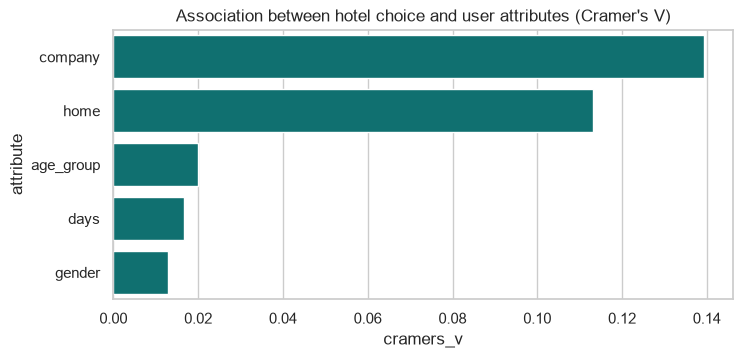

In [46]:
# Select your features wisely to avoid overfitting
# how strongly is hotel choice linked to each user attribute? (Cramer's V from a chi-square test)
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2, p, _, _ = stats.chi2_contingency(table)
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p

rows = []
for col in ["company", "home", "age_group", "gender", "days"]:
    v, p = cramers_v(stays[col], stays["name"])
    rows.append({"attribute": col, "cramers_v": round(v, 4), "p_value": p})
assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
print(assoc.to_string(index=False))

plt.figure(figsize=(8, 3.5))
sns.barplot(data=assoc, x="cramers_v", y="attribute", color="teal")
plt.title("Association between hotel choice and user attributes (Cramer's V)")
plt.show()

##### What all feature selection methods have you used  and why?

For a recommender the "features" are the signals used to score the hotels. First I measured how strongly hotel choice is linked to each user attribute with a chi-square test and Cramer's V. Company (0.139) and home city (0.113) have a clear link, age group is tiny (0.020), and stay length (0.017, p = 0.09) and gender (0.013, p = 0.63) have none. Then I compared the remaining signals inside the models on the validation folds: the segment choice in model 1, history and price similarity in model 2, and CF, history and home city in model 3.

##### Which all features you found important and why?

The home city is the most important feature, mainly because it tells us which hotel the user will not book, and home city popularity ended up as the strongest scoring signal. The user's own history matters less for accuracy but it is what makes the list personal. Gender, age and stay length were dropped because they showed no real link to hotel choice. I went with home city over company even though company has a slightly higher Cramer's V, because home city popularity scored better on validation (0.380 against 0.373 HitRate@3) and it can be known for a new user from their first flight.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

raw counts
name      Hotel A  Hotel AF  Hotel AU  Hotel BD  Hotel BP  Hotel BW  Hotel CB  Hotel K  Hotel Z
userCode                                                                                       
950             0         1         0         0         0         0         0        1        1
1104            0         6        10         7        13        16        12        6        6

after turning them into shares
name      Hotel A  Hotel AF  Hotel AU  Hotel BD  Hotel BP  Hotel BW  Hotel CB  Hotel K  Hotel Z
userCode                                                                                       
950           0.0     0.333     0.000     0.000     0.000     0.000     0.000    0.333    0.333
1104          0.0     0.079     0.132     0.092     0.171     0.211     0.158    0.079    0.079


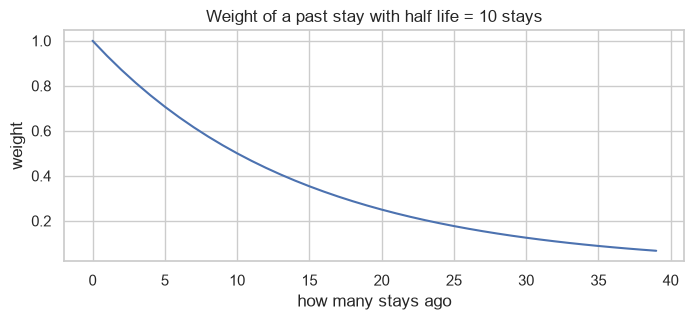

In [47]:
# Transform Your data
# raw counts are on very different scales (1 to 76 stays), so each user's row is turned into shares that sum to 1
counts = pd.crosstab(stays["userCode"], stays["name"])
shares = counts.div(counts.sum(axis=1), axis=0)

light, heavy = user_summary.sort_values("n_stays").iloc[[50, -1]]["userCode"]
print("raw counts")
print(counts.loc[[light, heavy]])
print("\nafter turning them into shares")
print(shares.loc[[light, heavy]].round(3))

# the recency weight used with a half life of 10 stays
ages = np.arange(0, 40)
plt.figure(figsize=(8, 3))
plt.plot(ages, 0.5 ** (ages / 10))
plt.title("Weight of a past stay with half life = 10 stays")
plt.xlabel("how many stays ago")
plt.ylabel("weight")
plt.show()

Yes. The raw stay counts depend a lot on how much someone travels (user 1104 has 76 stays and user 950 only 3), so I turned each user's counts into shares that add up to 1. That way a heavy and a light user with the same taste get the same vector. I also tried a recency weight with a half life (with a half life of 10, a stay 10 bookings ago counts half as much as the latest one), because chart 5 showed behaviour changing over time. I didn't use log or power transforms since none of the model inputs are skewed numbers.

### 6. Data Scaling

In [48]:
# Scaling your data
# all three score parts are shares between 0 and 1, so the blend weights are comparable
parts = {
    "history share": history_scores(stays, all_users, hotel_ids),
    "cf score": cf_scores(stays, all_users, hotel_ids, n_components=3),
}
overall_pop, city_pop = popularity_by_city(stays, home, len(hotel_ids))
parts["home city popularity"] = np.vstack([city_pop.get(home.get(u), overall_pop) for u in all_users])
for name, m in parts.items():
    print(f"{name:<22} min {m.min():.3f}   max {m.max():.3f}   mean row sum {m.sum(axis=1).mean():.3f}")

history share          min 0.000   max 1.000   mean row sum 1.000
cf score               min -0.137   max 0.967   mean row sum 0.999
home city popularity   min 0.000   max 0.137   mean row sum 1.000


##### Which method have you used to scale you data and why?

I didn't need a StandardScaler or MinMaxScaler. The parts of the score are already on a similar 0 to 1 scale because they are all shares: the history share goes from 0 to 1, the home city popularity from 0 to 0.137, and the CF score from -0.137 to 0.967 (it can be a bit negative because it's a low rank reconstruction). Every row adds up to about 1, so the blend weights decide how much each part counts and no extra scaling is needed.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not for the inputs, there are only 9 hotels. But dimensionality reduction is the core of the collaborative filtering model: TruncatedSVD squeezes the user x hotel matrix into a few "taste" components and rebuilds it, so hotels that similar users book get a higher score. The chart shows the variance is spread almost evenly over the components (2 components explain 16.8% and 5 explain 56.9%), which means there are no strong shared taste patterns. The first component explains only 0.2% because it mostly captures the average row, as TruncatedSVD doesn't centre the data.

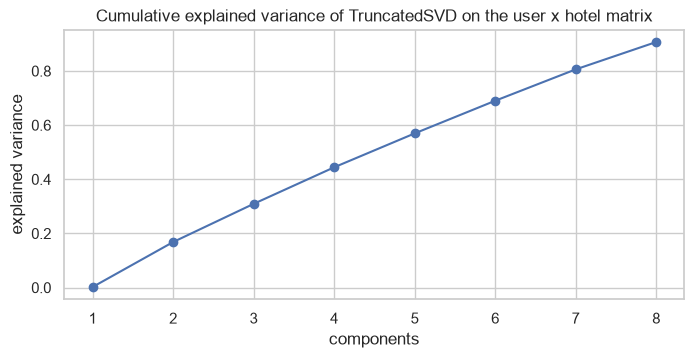

1    0.002
2    0.168
3    0.309
4    0.444
5    0.569
6    0.690
7    0.806
8    0.907
Name: cumulative explained variance, dtype: float64


In [49]:
# DImensionality Reduction (If needed)
# how much of the user x hotel share matrix can a few components explain?
svd_full = TruncatedSVD(n_components=8, random_state=RANDOM_STATE).fit(shares.values)
explained = np.cumsum(svd_full.explained_variance_ratio_)

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 9), explained, marker="o")
plt.title("Cumulative explained variance of TruncatedSVD on the user x hotel matrix")
plt.xlabel("components")
plt.ylabel("explained variance")
plt.show()
print(pd.Series(explained.round(3), index=range(1, 9), name="cumulative explained variance"))

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

TruncatedSVD from scikit-learn, used in model 3. I picked it over PCA because it works on the raw (not centred) user x hotel matrix, which is the usual setup for matrix factorisation in recommenders, and it also works on sparse matrices if the catalog grows. The number of components (2, 3 or 5) is tuned on validation.

### 8. Data Splitting

In [50]:
# Split your data to train and test. Choose Splitting ratio wisely.
# chronological leave-last-out: for every user the most recent stay is the test target,
# the 5 stays before it are used one at a time as validation targets (rolling validation).
# the model only ever sees stays that happened before the target stay.
stays["pos_from_end"] = stays.groupby("userCode").cumcount(ascending=False)
n_per_user = stays.groupby("userCode").size()
eligible_users = set(n_per_user[n_per_user >= 5].index)

def make_fold(level):
    """level 0 = last stay of each user, level 1 = second last, ..."""
    train = stays[stays["pos_from_end"] > level]
    target = stays[(stays["pos_from_end"] == level) & stays["userCode"].isin(eligible_users)]
    users_ = target["userCode"].tolist()
    return {"level": level, "train": train, "users": users_,
            "target": target["hotel_id"].to_numpy(),
            "homes": [home.get(u) for u in users_]}

VAL_LEVELS = [1, 2, 3, 4, 5]
FOLDS = {level: make_fold(level) for level in [0] + VAL_LEVELS}

print("users used for evaluation:", len(eligible_users))
for level, fold in FOLDS.items():
    name = "test" if level == 0 else f"validation {level}"
    print(f"{name:<13} train stays: {len(fold['train']):>6}   target stays: {len(fold['target'])}")

users used for evaluation: 1228
test          train stays:  39242   target stays: 1228
validation 1  train stays:  37954   target stays: 1228
validation 2  train stays:  36686   target stays: 1228
validation 3  train stays:  35441   target stays: 1228
validation 4  train stays:  34213   target stays: 1228
validation 5  train stays:  33005   target stays: 1208


##### What data splitting ratio have you used and why? 

I didn't use a random split. For a recommender the fair test is to predict a user's future booking from their past ones, so I used a chronological leave-last-out split. For each of the 1,228 users with at least 5 stays, the last stay is the test target (1,228 targets) and the 5 stays before it are rolling validation targets (6,120 in total). For every target the model only sees the stays that happened before it. A random 80/20 split would let the model see later stays while predicting earlier ones, which leaks the future.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Not really. The most booked hotel (Hotel K, 12.56%) is only 1.53 times the least booked one (Hotel A, 8.21%). What I did care about is popularity bias: a recommender can easily end up showing the same 3 popular hotels to everyone. That's why I track catalog coverage and personalization next to the accuracy metrics.

In [51]:
# Handling Imbalanced Dataset (If needed)
share = stays["name"].value_counts(normalize=True).mul(100).round(2)
print(share)
print("\nratio most / least booked hotel:", round(share.max() / share.min(), 2))

name
Hotel K     12.56
Hotel CB    12.40
Hotel BD    11.91
Hotel AF    11.91
Hotel AU    11.02
Hotel BP    10.94
Hotel BW    10.69
Hotel Z     10.37
Hotel A      8.21
Name: proportion, dtype: float64

ratio most / least booked hotel: 1.53


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No resampling was needed, oversampling bookings would just change the real popularity. Instead I dealt with popularity bias in model selection: when several settings had the same accuracy within one standard error I picked the most personalised one, and I checked that the final model recommends all 9 hotels (coverage = 1.0).

## ***7. ML Model Implementation***

In [52]:
# helper functions shared by all three models
N_HOTELS = len(hotel_ids)
HOTEL_PLACES = hotel_info["place"].to_numpy(dtype=object)
HOTEL_PRICES = hotel_info["price_per_day"].to_numpy(dtype=float)
RANDOM_HIT_RATE = 3 / N_HOTELS   # what random top 3 picks would get

def blend(hist, cf, pop, home_mask, params):
    return (params["w_hist"] * hist + params["w_cf"] * cf + params["w_pop"] * pop
            - params["home_penalty"] * home_mask)

_cache = {}
def cached(key, fn):
    if key not in _cache:
        _cache[key] = fn()
    return _cache[key]

def fold_hist(fold, half_life):
    return cached(("hist", fold["level"], half_life),
                  lambda: history_scores(fold["train"], fold["users"], hotel_ids, half_life))

def fold_cf(fold, n_components):
    return cached(("cf", fold["level"], n_components),
                  lambda: cf_scores(fold["train"], fold["users"], hotel_ids, n_components))

def fold_home_pop(fold):
    def build():
        overall, by_city = popularity_by_city(fold["train"], home, N_HOTELS)
        return np.vstack([by_city.get(c, overall) for c in fold["homes"]])
    return cached(("home_pop", fold["level"]), build)

def fold_home_mask(fold):
    return cached(("home_mask", fold["level"]),
                  lambda: (HOTEL_PLACES[None, :] == np.array(fold["homes"], dtype=object)[:, None]).astype(float))

def rank_metrics(scores, target, k=3):
    """HitRate@k, Precision@k, NDCG@k, catalog coverage and personalization of the top k lists."""
    top = np.argsort(-scores, axis=1, kind="stable")[:, :k]
    hit = top == target[:, None]
    found = hit.any(axis=1)
    ndcg = np.where(found, 1 / np.log2(hit.argmax(axis=1) + 2), 0)
    # personalization = 1 - average overlap between the lists of two random users
    rng = np.random.default_rng(RANDOM_STATE)
    a, b = rng.integers(0, len(top), 3000), rng.integers(0, len(top), 3000)
    overlap = np.mean([len(set(top[i]) & set(top[j])) / k for i, j in zip(a, b)])
    return {"hit@3": found.mean(), "precision@3": found.mean() / k, "ndcg@3": ndcg.mean(),
            "coverage": len(np.unique(top)) / N_HOTELS, "personalization": 1 - overlap}

def evaluate(score_fn, levels, **params):
    """Average metrics of a scoring function over the given folds."""
    return pd.DataFrame([rank_metrics(score_fn(FOLDS[l], **params), FOLDS[l]["target"]) for l in levels]).mean().to_dict()

def grid_search(score_fn, grid):
    """Evaluate every config on the validation folds."""
    return pd.DataFrame([{**p, **evaluate(score_fn, VAL_LEVELS, **p)} for p in grid])

N_VAL_TARGETS = sum(len(FOLDS[l]["target"]) for l in VAL_LEVELS)

def pick_config(results, param_names):
    """Best validation hit@3, and among the configs within one standard error of it
    take the most personalised one (the differences inside 1 SE are just noise)."""
    best = results["hit@3"].max()
    se = np.sqrt(best * (1 - best) / N_VAL_TARGETS)
    near = results[results["hit@3"] >= best - se]
    chosen = near.sort_values(["personalization", "hit@3"], ascending=False).iloc[0]
    params = {}
    for p in param_names:
        v = chosen[p]
        params[p] = None if pd.isna(v) else (v.item() if hasattr(v, "item") else v)
    return params, se

def metric_chart(metrics, title):
    m = pd.Series(metrics)[["hit@3", "precision@3", "ndcg@3", "coverage", "personalization"]]
    plt.figure(figsize=(8, 3.5))
    ax = sns.barplot(x=m.index, y=m.values, color="cornflowerblue")
    ax.bar_label(ax.containers[0], fmt="%.3f")
    plt.axhline(RANDOM_HIT_RATE, color="red", linestyle="--", label=f"random hit@3 = {RANDOM_HIT_RATE:.3f}")
    plt.ylim(0, 1.1)
    plt.title(title)
    plt.legend()
    plt.show()

results_table = {}   # test metrics of every model, filled as we go

### ML Model - 1

In [53]:
# ML Model - 1 Implementation
# popularity baseline: recommend the 3 most booked hotels to everyone
def popularity_model(fold, segment=None):
    train = fold["train"]
    overall = np.bincount(train["hotel_id"], minlength=N_HOTELS) / len(train)
    if segment is None:
        return np.tile(overall, (len(fold["users"]), 1))
    # popularity inside the user's own segment (company, age group, gender or home city)
    groups = train["userCode"].map(user_attr[segment])
    by_group = {g: np.bincount(grp["hotel_id"], minlength=N_HOTELS) / len(grp) for g, grp in train.groupby(groups)}
    keys = user_attr.loc[fold["users"], segment]
    return np.vstack([by_group.get(k, overall) for k in keys])

# Fit the Algorithm + Predict on the model (here fitting = counting bookings in the training stays)
pop_test = evaluate(popularity_model, [0])
results_table["1. popularity (overall)"] = pop_test
pd.Series(pop_test).round(4)

hit@3              0.3510
precision@3        0.1170
ndcg@3             0.2524
coverage           0.3333
personalization    0.0000
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

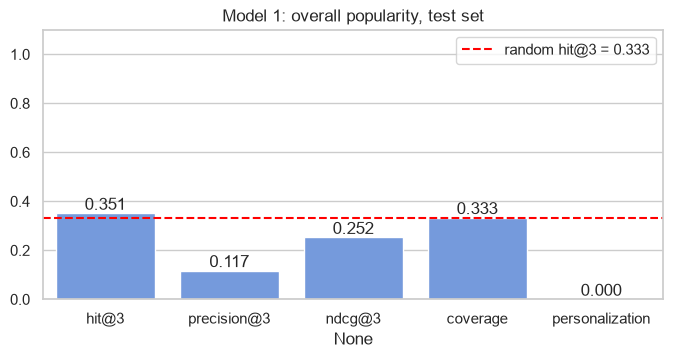

In [54]:
# Visualizing evaluation Metric Score chart
metric_chart(pop_test, "Model 1: overall popularity, test set")

Model 1 is a popularity baseline. It counts how often each hotel was booked in the training stays and recommends the 3 most booked hotels to every user. There is nothing personal in it, so it's the bar the other models have to beat.

On the test set (the last stay of 1,228 users) it gets HitRate@3 = 0.351, so the hotel the user actually booked next was in the top 3 for 35.1% of users. Precision@3 is 0.117 (at most one of the 3 suggestions can be the booked hotel), NDCG@3 is 0.252, coverage is only 0.333 because the same 3 hotels (K, CB and BD) are shown to everyone, and personalization is 0. The hit rate is barely above the 0.333 random line, so plain popularity helps very little here.

#### 2. Cross- Validation & Hyperparameter Tuning

  segment  hit@3  precision@3  ndcg@3  coverage  personalization
  overall 0.3718       0.1239  0.2662    0.3333           0.0000
  company 0.3729       0.1243  0.2678    0.9333           0.5446
age_group 0.3744       0.1248  0.2672    0.4444           0.2118
   gender 0.3676       0.1225  0.2623    0.4444           0.2078
     home 0.3798       0.1266  0.2704    0.8444           0.5408

chosen: {'segment': 'home'} (1 SE = 0.0062)


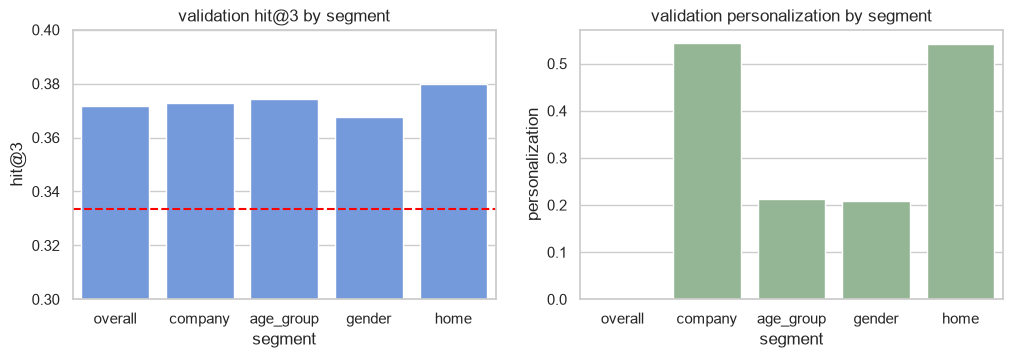

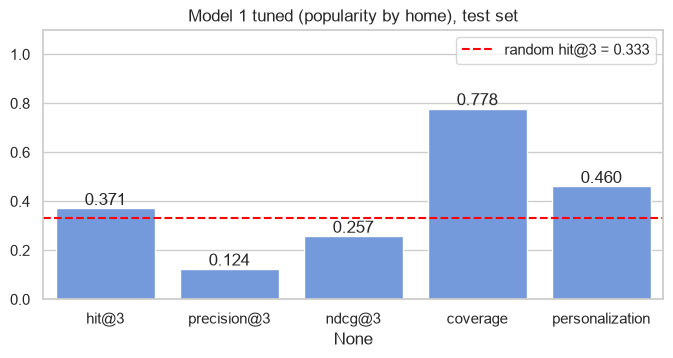

In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# the only setting here is which segment the popularity is computed in
pop_grid = [{"segment": s} for s in [None, "company", "age_group", "gender", "home"]]
pop_results = grid_search(popularity_model, pop_grid)
pop_best, pop_se = pick_config(pop_results, ["segment"])

pop_results["segment"] = pop_results["segment"].fillna("overall")
print(pop_results.round(4).to_string(index=False))
print("\nchosen:", pop_best, f"(1 SE = {pop_se:.4f})")

# Fit the Algorithm + Predict on the model
pop_tuned_test = evaluate(popularity_model, [0], **pop_best)
results_table[f"1. popularity by {pop_best['segment'] or 'overall'} (tuned)"] = pop_tuned_test

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.barplot(data=pop_results, x="segment", y="hit@3", ax=axes[0], color="cornflowerblue")
axes[0].axhline(RANDOM_HIT_RATE, color="red", linestyle="--")
axes[0].set_ylim(0.3, 0.4)
axes[0].set_title("validation hit@3 by segment")
sns.barplot(data=pop_results, x="segment", y="personalization", ax=axes[1], color="darkseagreen")
axes[1].set_title("validation personalization by segment")
plt.show()
metric_chart(pop_tuned_test, f"Model 1 tuned (popularity by {pop_best['segment']}), test set")

##### Which hyperparameter optimization technique have you used and why?

A grid search over the segment the popularity is computed in (overall, company, age group, gender and home city), scored on the 5 rolling validation folds, which works like time series cross validation. There are only 5 options so a full grid is cheap. I take the best HitRate@3, and if other options are within one standard error (0.0062) of it, the most personalised of those.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. Popularity by home city was the best option on validation with HitRate@3 = 0.380 (overall popularity was 0.372). On the test set HitRate@3 went from 0.351 to 0.371, NDCG@3 from 0.252 to 0.257, coverage from 0.333 to 0.778 and personalization from 0 to 0.460. The gain comes from the home city effect, people now mostly get hotels outside their own city.

### ML Model - 2

In [56]:
# ML Model - 2 Implementation
# content based / user history model:
#   - the user's own history (share of stays per hotel, recent stays can weigh more)
#   - plus hotels with a similar price to the ones they use (content part)
#   - plus a bit of overall popularity so new hotels still get a chance
def content_model(fold, half_life=None, beta=0.3, alpha=0.0, bandwidth=50):
    hist = fold_hist(fold, half_life)
    price_sim = np.exp(-np.abs(HOTEL_PRICES[:, None] - HOTEL_PRICES[None, :]) / bandwidth)
    content = hist @ price_sim
    content = content / np.maximum(content.sum(axis=1, keepdims=True), 1e-12)
    overall = np.bincount(fold["train"]["hotel_id"], minlength=N_HOTELS) / len(fold["train"])
    return (1 - beta) * hist + beta * content + alpha * overall

# Fit the Algorithm + Predict on the model (default settings)
content_default = {"half_life": None, "beta": 0.3, "alpha": 0.0, "bandwidth": 50}
content_test = evaluate(content_model, [0], **content_default)
results_table["2. user history + content (default)"] = content_test
pd.Series(content_test).round(4)

hit@3              0.3664
precision@3        0.1221
ndcg@3             0.2638
coverage           1.0000
personalization    0.6530
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

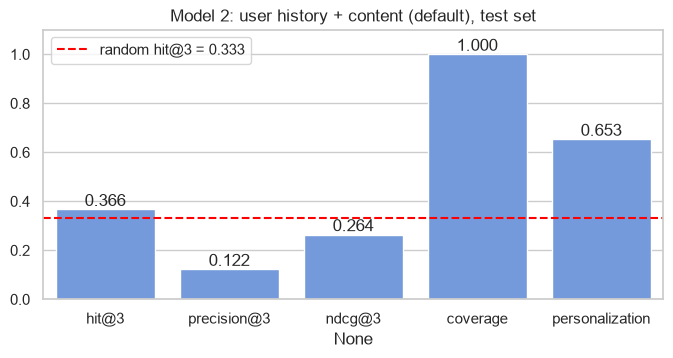

In [57]:
# Visualizing evaluation Metric Score chart
metric_chart(content_test, "Model 2: user history + content (default), test set")

Model 2 is a content based / user history model. A hotel's score mixes three things: the share of the user's own stays at that hotel (optionally with a recency weight), a content part that also gives points to hotels with a similar price to the ones the user uses (price similarity = exp(-price difference / bandwidth)), and a small amount of overall popularity.

With the default settings (no recency, 30% content, no popularity) it gets HitRate@3 = 0.366, Precision@3 = 0.122 and NDCG@3 = 0.264 on test. That is better than overall popularity (0.351), and it's much more personal: coverage is 1.0 (every hotel gets recommended to someone) and personalization is 0.653.

#### 2. Cross- Validation & Hyperparameter Tuning

configs tried: 96
 half_life  beta  alpha  bandwidth  hit@3  precision@3  ndcg@3  coverage  personalization
      10.0   0.0    1.0         80 0.3756       0.1252  0.2640       1.0           0.6373
      10.0   0.0    1.0         30 0.3756       0.1252  0.2640       1.0           0.6373
       5.0   0.0    2.0         80 0.3750       0.1250  0.2652       1.0           0.6318
       5.0   0.0    2.0         30 0.3750       0.1250  0.2652       1.0           0.6318
       5.0   0.0    1.0         80 0.3740       0.1247  0.2650       1.0           0.6473
       5.0   0.0    1.0         30 0.3740       0.1247  0.2650       1.0           0.6473
      10.0   0.0    2.0         80 0.3738       0.1246  0.2631       1.0           0.6102
      10.0   0.0    2.0         30 0.3738       0.1246  0.2631       1.0           0.6102

chosen: {'half_life': 5.0, 'beta': 0.0, 'alpha': 0.5, 'bandwidth': 30.0} (1 SE = 0.0062)


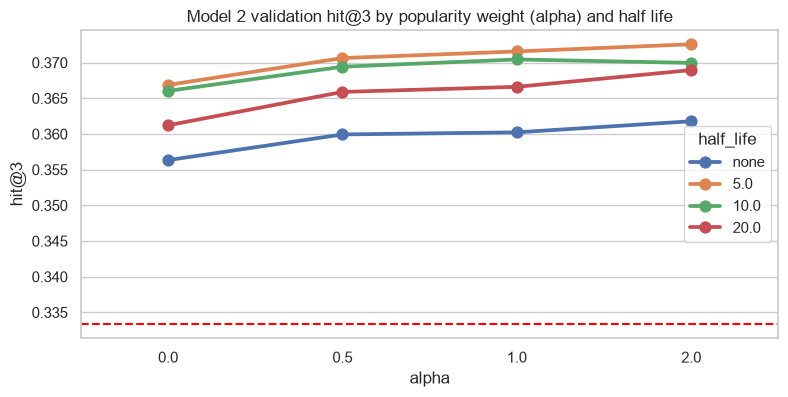

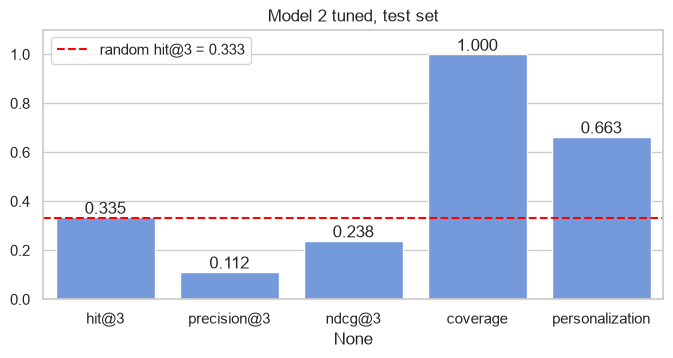

In [58]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
import itertools
content_grid = [dict(zip(["half_life", "beta", "alpha", "bandwidth"], v))
                for v in itertools.product([None, 5, 10, 20], [0, 0.3, 0.6], [0, 0.5, 1, 2], [30, 80])]
content_results = grid_search(content_model, content_grid)
print("configs tried:", len(content_results))
print(content_results.sort_values("hit@3", ascending=False).head(8).round(4).to_string(index=False))

content_best, content_se = pick_config(content_results, ["half_life", "beta", "alpha", "bandwidth"])
print("\nchosen:", content_best, f"(1 SE = {content_se:.4f})")

# Fit the Algorithm + Predict on the model
content_tuned_test = evaluate(content_model, [0], **content_best)
results_table["2. user history + content (tuned)"] = content_tuned_test

# effect of the popularity weight and recency, averaged over the other settings
plot_df = content_results.assign(half_life=content_results["half_life"].fillna("none").astype(str))
plt.figure(figsize=(9, 4))
sns.pointplot(data=plot_df, x="alpha", y="hit@3", hue="half_life", errorbar=None)
plt.axhline(RANDOM_HIT_RATE, color="red", linestyle="--", label="random")
plt.title("Model 2 validation hit@3 by popularity weight (alpha) and half life")
plt.show()
metric_chart(content_tuned_test, "Model 2 tuned, test set")

##### Which hyperparameter optimization technique have you used and why?

A grid search over 96 combinations: half life (none, 5, 10 or 20 stays), content weight beta (0, 0.3, 0.6), popularity weight alpha (0, 0.5, 1, 2) and price bandwidth (30, 80), all scored on the 5 rolling validation folds. Grid search was fine because each combination takes milliseconds once the history matrices are cached, and it lets me see the effect of each setting.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

On validation, yes: the best combination reached HitRate@3 = 0.376, and the chosen one (half life 5, no content part, popularity weight 0.5) was within one standard error of it and more personal. The content weight ended at 0, so price similarity did not help, people don't stick to one price level. On the test set the tuned model got 0.335 against 0.366 for the default. That drop is inside the noise of a single test set of 1,228 users (its 95% interval is about +/- 0.025), and it's the main reason I trust the 6,120 validation targets more than the test set for choosing settings.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- HitRate@3: how often the hotel the customer actually books is among the 3 we showed. For the business this is the chance that the recommendation box leads to a booking.
- Precision@3: the share of the 3 shown hotels that were relevant. With one target per user it's just HitRate@3 / 3.
- NDCG@3: gives more credit when the right hotel is in position 1 instead of 3, which matters because people click the first item the most.
- Coverage: the share of the 9 hotels that get recommended to anyone. A low value means some partner hotels never get any exposure.
- Personalization: 1 minus the average overlap between the lists of two random users. It shows whether customers get their own list or one generic list. A model with a good hit rate and zero personalization is really just a "most popular" banner.

### ML Model - 3

In [59]:
# ML Model - 3 Implementation
# collaborative filtering with TruncatedSVD, then a hybrid that also mixes in
# the user's history, home city popularity and a penalty for the hotel in the home city
def hybrid_model(fold, half_life=None, n_components=3, w_hist=0.0, w_cf=1.0, w_pop=0.0, home_penalty=0.0):
    params = {"w_hist": w_hist, "w_cf": w_cf, "w_pop": w_pop, "home_penalty": home_penalty}
    return blend(fold_hist(fold, half_life), fold_cf(fold, int(n_components)),
                 fold_home_pop(fold), fold_home_mask(fold), params)

# Fit the Algorithm + Predict on the model (default = plain SVD collaborative filtering)
cf_default = {"half_life": None, "n_components": 3, "w_hist": 0.0, "w_cf": 1.0, "w_pop": 0.0, "home_penalty": 0.0}
cf_test = evaluate(hybrid_model, [0], **cf_default)
results_table["3. SVD collaborative filtering (default)"] = cf_test
pd.Series(cf_test).round(4)

hit@3              0.3567
precision@3        0.1189
ndcg@3             0.2498
coverage           1.0000
personalization    0.5883
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

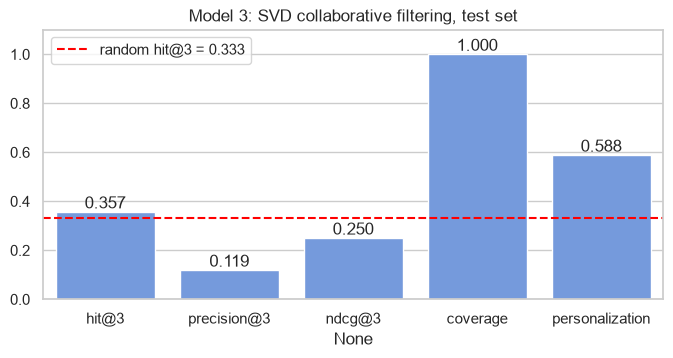

In [60]:
# Visualizing evaluation Metric Score chart
metric_chart(cf_test, "Model 3: SVD collaborative filtering, test set")

Model 3 starts from collaborative filtering. I take the user x hotel matrix of shares, compress it with TruncatedSVD into a few components and rebuild it. Hotels that users with a similar pattern book get a higher score, even if this user hasn't booked them much.

The tuned version is a hybrid that blends four parts: the user's history (with recency), the SVD score, the popularity of each hotel among people from the same home city, and a penalty for the hotel in the user's home city. The weights decide how much each part counts.

The default plain SVD model (3 components, no other parts) gets HitRate@3 = 0.357, Precision@3 = 0.119 and NDCG@3 = 0.250 on test, with coverage 1.0 and personalization 0.588. That's a bit better than overall popularity but not better than model 2's default, which fits chart 13: from a CF point of view the hotels are all very similar.

#### 2. Cross- Validation & Hyperparameter Tuning

configs tried: 1128
 half_life  n_components  w_hist  w_cf  w_pop  home_penalty  hit@3  precision@3  ndcg@3  coverage  personalization
      20.0             2     0.0  0.25    1.0             0 0.3853       0.1284  0.2727    0.9778           0.5019
       NaN             2     0.0  0.25    1.0             0 0.3853       0.1284  0.2727    0.9778           0.5019
       NaN             2     0.0  0.50    2.0             1 0.3853       0.1284  0.2727    0.9778           0.5018
       NaN             2     0.0  0.50    2.0             0 0.3853       0.1284  0.2727    0.9778           0.5019
      20.0             2     0.0  0.50    2.0             1 0.3853       0.1284  0.2727    0.9778           0.5018
      20.0             2     0.0  0.50    2.0             0 0.3853       0.1284  0.2727    0.9778           0.5019
      20.0             2     0.0  0.25    1.0             1 0.3853       0.1284  0.2727    0.9778           0.5018
      10.0             2     0.0  0.50    2.0             1 

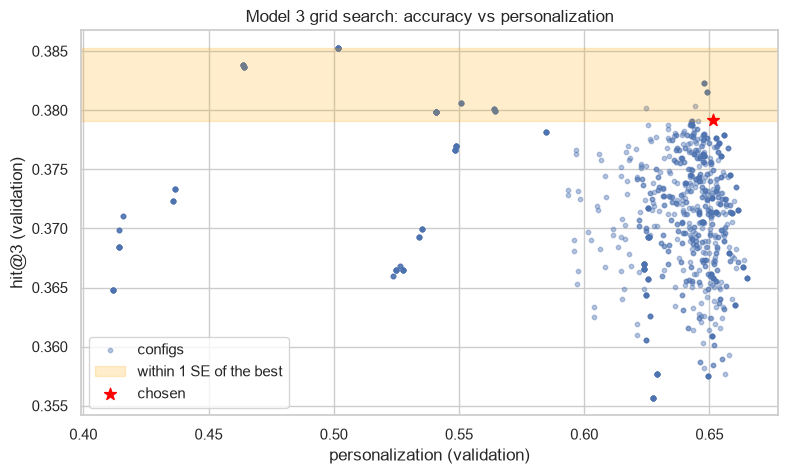

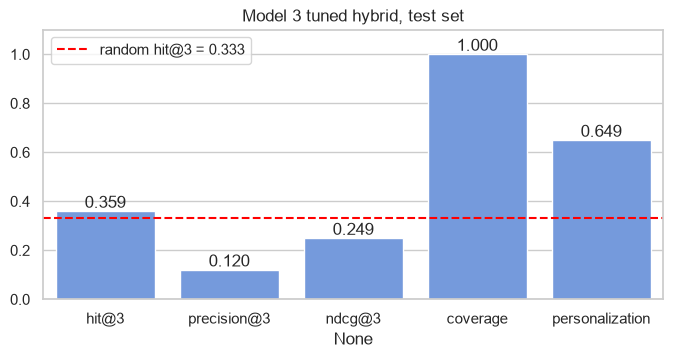

In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
hybrid_names = ["half_life", "n_components", "w_hist", "w_cf", "w_pop", "home_penalty"]
hybrid_grid = [dict(zip(hybrid_names, v)) for v in itertools.product(
    [None, 5, 10, 20], [2, 3, 5], [0, 0.5, 1], [0, 0.25, 0.5, 1], [0, 0.5, 1, 2], [0, 1])]
hybrid_grid = [p for p in hybrid_grid if p["w_hist"] + p["w_cf"] + p["w_pop"] > 0]
hybrid_results = grid_search(hybrid_model, hybrid_grid)
print("configs tried:", len(hybrid_results))
print(hybrid_results.sort_values("hit@3", ascending=False).head(8).round(4).to_string(index=False))

hybrid_best, hybrid_se = pick_config(hybrid_results, hybrid_names)
hybrid_best["n_components"] = int(hybrid_best["n_components"])
print("\nchosen:", hybrid_best, f"(1 SE = {hybrid_se:.4f})")
print("configs within 1 SE of the best:", (hybrid_results["hit@3"] >= hybrid_results["hit@3"].max() - hybrid_se).sum())

# Fit the Algorithm + Predict on the model
hybrid_test = evaluate(hybrid_model, [0], **hybrid_best)
results_table["3. hybrid (tuned)"] = hybrid_test

# every config: accuracy vs how personal the lists are
best_hit = hybrid_results["hit@3"].max()
plt.figure(figsize=(9, 5))
plt.scatter(hybrid_results["personalization"], hybrid_results["hit@3"], s=10, alpha=0.4, label="configs")
plt.axhspan(best_hit - hybrid_se, best_hit, color="orange", alpha=0.2, label="within 1 SE of the best")
chosen_row = evaluate(hybrid_model, VAL_LEVELS, **hybrid_best)
plt.scatter(chosen_row["personalization"], chosen_row["hit@3"], color="red", s=80, marker="*", label="chosen")
plt.xlabel("personalization (validation)")
plt.ylabel("hit@3 (validation)")
plt.title("Model 3 grid search: accuracy vs personalization")
plt.legend()
plt.show()
metric_chart(hybrid_test, "Model 3 tuned hybrid, test set")

##### Which hyperparameter optimization technique have you used and why?

A grid search over 1,128 combinations of half life, number of SVD components (2, 3, 5), the weights of the history, CF and popularity parts and whether the home city penalty is on, all scored on the 5 validation folds. To keep it fast I cache the history, CF and popularity matrices per fold, so each combination is just a weighted sum and a sort. 161 combinations were within one standard error (0.0062) of the best one, so I picked the most personalised of those.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The best validation HitRate@3 was 0.385 and the chosen setting got 0.379 (half life 10, history weight 0.5, popularity weight 0.5, home penalty on, CF weight 0). On the test set HitRate@3 went from 0.357 to 0.359, personalization from 0.588 to 0.649, and coverage stayed at 1.0. The interesting part is that the search gave CF a weight of 0: once home city popularity and history are in the score, the SVD part doesn't add anything.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

My main metric is HitRate@3, with NDCG@3 for the ranking quality, because that is closest to the business goal: the customer books one of the hotels we suggested. But on this data all models land in a narrow band (0.33 to 0.37 on test), so I also used coverage and personalization. Those decide whether the recommender does something useful, showing different users different hotels and giving all 9 partner hotels some exposure, instead of being a fixed top 3 list.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

In [62]:
# test results of all models side by side
summary = pd.DataFrame(results_table).T[["hit@3", "precision@3", "ndcg@3", "coverage", "personalization"]]
summary.round(4)

,hit@3,precision@3,ndcg@3,coverage,personalization
1. popularity (overall),0.3510,0.1170,0.2524,0.3333,0.0000
1. popularity by home (tuned),0.3705,0.1235,0.2573,0.7778,0.4604
2. user history + content (default),0.3664,0.1221,0.2638,1.0000,0.6530
2. user history + content (tuned),0.3347,0.1116,0.2385,1.0000,0.6629
3. SVD collaborative filtering (default),0.3567,0.1189,0.2498,1.0000,0.5883
3. hybrid (tuned),0.3591,0.1197,0.2489,1.0000,0.6490


                    model  hit@3    low   high
     popularity (overall) 0.3510 0.3249 0.3762
       popularity by home 0.3705 0.3453 0.3990
history + content (tuned) 0.3347 0.3094 0.3599
           hybrid (tuned) 0.3591 0.3298 0.3860


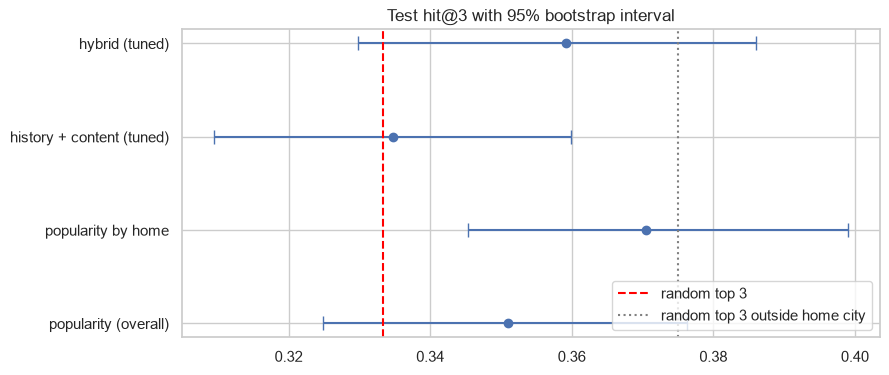

In [63]:
# bootstrap 95% confidence interval of test hit@3 for the tuned models and the overall popularity baseline
def test_hits(score_fn, **params):
    fold = FOLDS[0]
    top = np.argsort(-score_fn(fold, **params), axis=1, kind="stable")[:, :3]
    return (top == fold["target"][:, None]).any(axis=1).astype(float)

final_models = {
    "popularity (overall)": test_hits(popularity_model),
    f"popularity by {pop_best['segment']}": test_hits(popularity_model, **pop_best),
    "history + content (tuned)": test_hits(content_model, **content_best),
    "hybrid (tuned)": test_hits(hybrid_model, **hybrid_best),
}
rng = np.random.default_rng(RANDOM_STATE)
ci_rows = []
for name, hits in final_models.items():
    boots = [hits[rng.integers(0, len(hits), len(hits))].mean() for _ in range(1000)]
    ci_rows.append({"model": name, "hit@3": hits.mean(), "low": np.percentile(boots, 2.5), "high": np.percentile(boots, 97.5)})
ci = pd.DataFrame(ci_rows)
print(ci.round(4).to_string(index=False))

plt.figure(figsize=(9, 4))
plt.errorbar(ci["hit@3"], ci["model"], xerr=[ci["hit@3"] - ci["low"], ci["high"] - ci["hit@3"]], fmt="o", capsize=5)
plt.axvline(RANDOM_HIT_RATE, color="red", linestyle="--", label="random top 3")
plt.axvline(3 / 8, color="grey", linestyle=":", label="random top 3 outside home city")
plt.title("Test hit@3 with 95% bootstrap interval")
plt.legend(loc="lower right")
plt.show()

I chose the tuned hybrid model (model 3).

On validation, which has 6,120 targets and is more reliable than the 1,228 test targets, it scored HitRate@3 = 0.379, the same as the best popularity model (0.380) and within one standard error of the best setting overall. On the test set the differences between the models are smaller than the noise, the 95% bootstrap intervals all overlap (popularity by home city 0.371 [0.345, 0.399], hybrid 0.359 [0.330, 0.386]). Since accuracy is a tie, I went with the model that is better as a product: it recommends all 9 hotels, gives each user their own list (personalization 0.65 against 0.46), can explain every suggestion ("you stayed here 9 times", "popular with travellers from Brasilia") and still falls back to popularity for new users.

I also want to be honest about the ceiling. Random picks from the 8 hotels outside the home city would give a hit rate of 3/8 = 0.375, and hypothesis 3 showed that users have very little personal preference. So no model can get much higher on this data, and the value of the recommender here is ranking and personalising sensibly more than raising the hit rate.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

              removed  hit@3  ndcg@3  coverage  personalization
nothing (final model) 0.3792  0.2663    1.0000           0.6512
               w_hist 0.3798  0.2704    0.8444           0.5408
                w_pop 0.3713  0.2622    1.0000           0.6588
         home_penalty 0.3773  0.2652    1.0000           0.6537


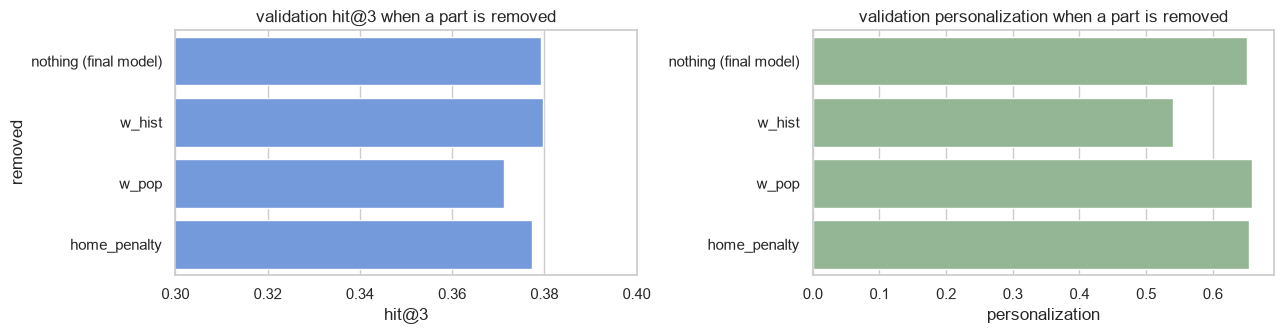

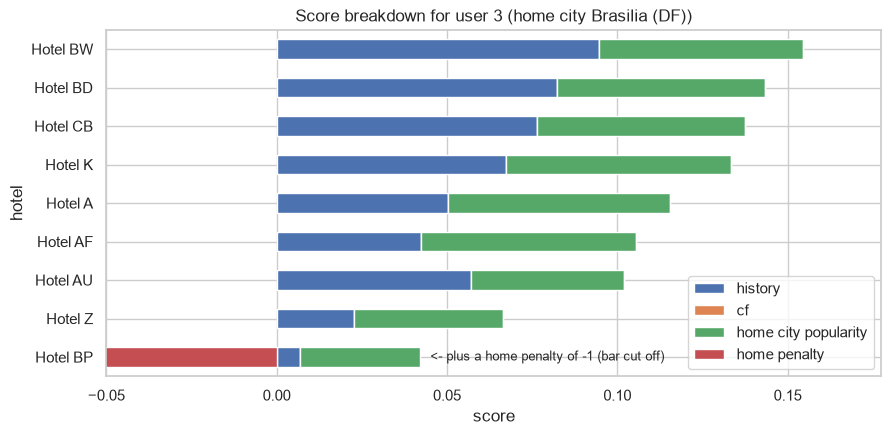

In [64]:
# explaining the final model: what happens if one part of the score is removed (validation folds)
FINAL_PARAMS = dict(hybrid_best)
base = evaluate(hybrid_model, VAL_LEVELS, **FINAL_PARAMS)
ablation = [{"removed": "nothing (final model)", **base}]
for part in ["w_hist", "w_cf", "w_pop", "home_penalty"]:
    if FINAL_PARAMS[part] == 0:
        continue
    ablation.append({"removed": part, **evaluate(hybrid_model, VAL_LEVELS, **{**FINAL_PARAMS, part: 0})})
ablation = pd.DataFrame(ablation)
print(ablation[["removed", "hit@3", "ndcg@3", "coverage", "personalization"]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sns.barplot(data=ablation, y="removed", x="hit@3", ax=axes[0], color="cornflowerblue")
axes[0].set_xlim(0.3, 0.4)
axes[0].set_title("validation hit@3 when a part is removed")
sns.barplot(data=ablation, y="removed", x="personalization", ax=axes[1], color="darkseagreen")
axes[1].set_title("validation personalization when a part is removed")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# score breakdown for one user: which part pushes each hotel up or down
u = 3
row = all_users.index(u)
hist_u = history_scores(stays, all_users, hotel_ids, FINAL_PARAMS["half_life"])[row]
cf_u = cf_scores(stays, all_users, hotel_ids, FINAL_PARAMS["n_components"])[row]
overall_pop, city_pop = popularity_by_city(stays, home, N_HOTELS)
pop_u = city_pop.get(home.get(u), overall_pop)
mask_u = (HOTEL_PLACES == home.get(u)).astype(float)
breakdown = pd.DataFrame({
    "history": FINAL_PARAMS["w_hist"] * hist_u,
    "cf": FINAL_PARAMS["w_cf"] * cf_u,
    "home city popularity": FINAL_PARAMS["w_pop"] * pop_u,
    "home penalty": -FINAL_PARAMS["home_penalty"] * mask_u,
}, index=hotel_info["hotel"])
breakdown = breakdown.loc[breakdown.sum(axis=1).sort_values(ascending=False).index]
ax = breakdown.plot(kind="barh", stacked=True, figsize=(10, 4.5))
ax.invert_yaxis()
# the home penalty bar (-1) would squash everything else, so the axis is cut at -0.05
ax.set_xlim(-0.05, breakdown.clip(lower=0).sum(axis=1).max() * 1.15)
for i, h in enumerate(breakdown.index):
    if breakdown.loc[h, "home penalty"] < 0:
        ax.text(breakdown.loc[h].clip(lower=0).sum() + 0.003, i, "<- plus a home penalty of -1 (bar cut off)", va="center", fontsize=9)
plt.title(f"Score breakdown for user {u} (home city {home.get(u)})")
plt.xlabel("score")
plt.show()

The final model scores every hotel for a user as:

score = 0.5 x history share (half life 10) + 0.5 x home city popularity - 1 x (hotel is in the user's home city)

and the 3 highest scores are the recommendations.

Since this is a scoring formula and not a black box, I explained it with an ablation study (remove one part, score again on validation) and a score breakdown for one user, instead of a tool like SHAP. Removing the popularity part drops HitRate@3 from 0.379 to 0.371, so popularity carries most of the accuracy. Removing the history part slightly raises the hit rate (0.380), but coverage falls from 1.0 to 0.84 and personalization from 0.65 to 0.54, so history is what makes the list personal. Removing the home penalty costs a little (0.377). The breakdown for user 3 shows the same thing: Hotel BP is in the user's home city Brasilia and is pushed to the bottom by the penalty, while the hotels the user books often (BW, BD and CB) move up through the history part.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [65]:
# Save the File
# same artifact format as src/recommender/model.py so the streamlit app can load it
DEFAULT_PARAMS = FINAL_PARAMS

def build_artifacts(hotels, flights, params=None, metrics=None):
    """Fit the recommender on all stays and pack everything the app needs into a dict."""
    params = {**DEFAULT_PARAMS, **(params or {})}
    stays = hotels.sort_values(["userCode", "date", "travelCode"]).reset_index(drop=True)
    table = hotel_table(stays)
    hotel_ids = {name: i for i, name in enumerate(table["hotel"])}
    stays["hotel_id"] = stays["name"].map(hotel_ids)

    home = home_cities(flights)
    user_ids = sorted(stays["userCode"].unique())
    overall, by_city = popularity_by_city(stays, home, len(table))

    counts = (pd.crosstab(stays["userCode"], stays["hotel_id"])
              .reindex(index=user_ids, columns=range(len(table)), fill_value=0).to_numpy())

    return {
        "params": params,
        "hotels": {
            "hotel": table["hotel"].tolist(),
            "place": table["place"].tolist(),
            "price_per_day": table["price_per_day"].astype(float).tolist(),
        },
        "user_row": {int(u): i for i, u in enumerate(user_ids)},
        "hist": history_scores(stays, user_ids, hotel_ids, params["half_life"]),
        "cf": cf_scores(stays, user_ids, hotel_ids, params["n_components"]),
        "visit_counts": counts,
        "home": {int(u): str(c) for u, c in home.items()},
        "pop_overall": overall,
        "pop_by_city": by_city,
        # past stays as plain columns so user_history can rebuild a dataframe
        "stays": {
            "userCode": stays["userCode"].to_numpy(dtype=int),
            "travelCode": stays["travelCode"].to_numpy(dtype=int),
            "hotel": stays["name"].to_numpy(dtype=object),
            "place": stays["place"].to_numpy(dtype=object),
            "days": stays["days"].to_numpy(dtype=int),
            "price_per_day": stays["price"].to_numpy(dtype=float),
            "total": stays["total"].to_numpy(dtype=float),
            "date": stays["date"].dt.strftime("%Y-%m-%d").to_numpy(dtype=object),
        },
        "metrics": metrics or {},
        "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }

final_metrics = {k.replace("@", "_at_"): round(float(v), 4) for k, v in results_table["3. hybrid (tuned)"].items()}
artifacts = build_artifacts(hotels, flights, params=FINAL_PARAMS, metrics=final_metrics)

MODEL_DIR = "../models" if os.path.isdir("../models") else "."
model_path = os.path.join(MODEL_DIR, "hotel_recommender.joblib")
try:
    joblib.dump(artifacts, model_path)
    print("saved to", model_path, f"({os.path.getsize(model_path) / 1e6:.2f} MB)")
except OSError as e:
    print("could not save the model:", e)
print("params:", artifacts["params"])

saved to ../models/hotel_recommender.joblib (3.59 MB)
params: {'half_life': 10.0, 'n_components': 2, 'w_hist': 0.5, 'w_cf': 0.0, 'w_pop': 0.5, 'home_penalty': 1.0}


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [66]:
# Load the File and predict unseen data.
def _hotel_frame(artifacts):
    return pd.DataFrame(artifacts["hotels"])


def popular_hotels(artifacts, k=3):
    """Most booked hotels overall, used for users we know nothing about."""
    df = _hotel_frame(artifacts)
    df["score"] = artifacts["pop_overall"]
    df["reason"] = [f"{share:.1%} of all bookings" for share in df["score"]]
    return df.sort_values("score", ascending=False).head(k).reset_index(drop=True)


def recommend(artifacts, user_code, k=3, max_price=None):
    """Top k hotels for a user as a dataframe: hotel, place, price_per_day, score, reason."""
    params = artifacts["params"]
    hotels = _hotel_frame(artifacts)
    n = len(hotels)
    user_code = int(user_code)
    row = artifacts["user_row"].get(user_code)
    home = artifacts["home"].get(user_code)

    if row is None and home is None:
        # cold start, no hotel or flight history at all
        recs = popular_hotels(artifacts, k=n)
        recs["reason"] = "popular choice overall (no history for this user yet)"
    else:
        hist = artifacts["hist"][row] if row is not None else np.zeros(n)
        cf = artifacts["cf"][row] if row is not None else np.zeros(n)
        visits = artifacts["visit_counts"][row] if row is not None else np.zeros(n, dtype=int)
        pop = artifacts["pop_by_city"].get(home, artifacts["pop_overall"])
        home_mask = (np.array(artifacts["hotels"]["place"], dtype=object) == home).astype(float)

        parts = {
            "hist": params["w_hist"] * hist,
            "cf": params["w_cf"] * cf,
            "pop": params["w_pop"] * pop,
        }
        recs = hotels.copy()
        recs["score"] = blend(hist, cf, pop, home_mask, params)

        reasons = []
        for i in range(n):
            if home_mask[i]:
                reasons.append("in your home city, so it is ranked lower")
                continue
            # the part of the score that adds the most decides the main reason
            driver = max(parts, key=lambda p: parts[p][i])
            if driver == "hist":
                msg = "one of your regular hotels"
            elif driver == "cf":
                msg = "travellers with a similar booking history like it"
            else:
                msg = f"popular with travellers from {home}" if home else "popular choice overall"
            msg += f", you stayed here {int(visits[i])} times" if visits[i] else ", you have not tried it yet"
            reasons.append(msg)
        recs["reason"] = reasons

    if max_price is not None:
        recs = recs[recs["price_per_day"] <= max_price]

    recs = recs.sort_values("score", ascending=False).head(k).reset_index(drop=True)
    recs["score"] = recs["score"].round(4)
    return recs[["hotel", "place", "price_per_day", "score", "reason"]]


def user_history(artifacts, user_code):
    """All past hotel stays of a user, newest first."""
    stays = pd.DataFrame(artifacts["stays"])
    mine = stays[stays["userCode"] == int(user_code)].drop(columns="userCode")
    return mine.sort_values("date", ascending=False).reset_index(drop=True)

loaded = joblib.load(model_path)

for user in [3, 600]:
    print(f"user {user}, home city {loaded['home'].get(user)}, last 3 stays:")
    display(user_history(loaded, user).head(3))
    print("recommended next:")
    display(recommend(loaded, user, k=3))

print("same user with a budget of 200 per day:")
display(recommend(loaded, 3, k=3, max_price=200))

# users the model has not seen: one flew but never booked a hotel, one is brand new
no_hotel_but_flew = [u for u in no_hotel_users if u in home.index][0]
print(f"user {no_hotel_but_flew} (flights but no hotel stays):")
display(recommend(loaded, no_hotel_but_flew, k=3))
print("brand new user 99999:")
display(recommend(loaded, 99999, k=3))

user 3, home city Brasilia (DF), last 3 stays:


,travelCode,hotel,place,days,price_per_day,total,date
0,424,Hotel CB,Rio de Janeiro (RJ),1,165.99,165.99,2023-07-13
1,419,Hotel BW,Campo Grande (MS),2,60.39,120.78,2023-06-08
2,418,Hotel AU,Recife (PE),1,312.83,312.83,2023-06-01


recommended next:


,hotel,place,price_per_day,score,reason
0,Hotel BW,Campo Grande (MS),60.39,0.1544,"one of your regular hotels, you stayed here 9 ..."
1,Hotel BD,Natal (RN),242.88,0.1434,"one of your regular hotels, you stayed here 11..."
2,Hotel CB,Rio de Janeiro (RJ),165.99,0.1375,"one of your regular hotels, you stayed here 7 ..."


user 600, home city Campo Grande (MS), last 3 stays:


...

,hotel,place,price_per_day,score,reason
0,Hotel BW,Campo Grande (MS),60.39,0.1544,"one of your regular hotels, you stayed here 9 ..."
1,Hotel CB,Rio de Janeiro (RJ),165.99,0.1375,"one of your regular hotels, you stayed here 7 ..."
2,Hotel AF,Sao Paulo (SP),139.10,0.1053,"popular with travellers from Brasilia (DF), yo..."


user 33 (flights but no hotel stays):


,hotel,place,price_per_day,score,reason
0,Hotel BW,Campo Grande (MS),60.39,0.0633,"popular with travellers from Aracaju (SE), you..."
1,Hotel A,Florianopolis (SC),313.02,0.0630,"popular with travellers from Aracaju (SE), you..."
2,Hotel K,Salvador (BH),263.41,0.0619,"popular with travellers from Aracaju (SE), you..."


brand new user 99999:


,hotel,place,price_per_day,score,reason
0,Hotel K,Salvador (BH),263.41,0.1256,popular choice overall (no history for this us...
1,Hotel CB,Rio de Janeiro (RJ),165.99,0.1240,popular choice overall (no history for this us...
2,Hotel BD,Natal (RN),242.88,0.1191,popular choice overall (no history for this us...


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

- The hotel data is small and very even: 9 hotels in 9 cities, fixed prices from 60 to 313 per day, and the same number of 1, 2, 3 and 4 day stays.
- People almost never book a hotel in their own city (3.96% against 11.1% by chance). This was the most useful signal for the recommender.
- Gender, age and stay length have no real link to which hotel someone books.
- Users have very little personal preference, and most of them have already tried 8 or 9 of the 9 hotels, so the next booking is hard to predict. All models ended between about 0.33 and 0.37 HitRate@3 on test, close to the 0.375 that random picks outside the home city would give.
- The final hybrid model (history + home city popularity + home city penalty) matches the best accuracy within noise, recommends all 9 hotels and gives each user their own list with a reason for every suggestion.
- The model is saved with joblib, rebuilt by src/recommender/train.py with MLflow tracking, and used in the Streamlit app.
- With richer data (ratings, reviews, more hotels per city) the same pipeline and evaluation should show a much bigger gap between the models. Separately, hotel bookings fell from 1,988 in October 2019 to 74 in June 2023, which the business should look into regardless of the recommender.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***